# Product category classification, stage 1: Graph Transformer on OGB features

Trains a Graph Transformer (GT) on the TAPE ogbn-products subset with the stage-1 setup, then compares it with the stage-1 GNNs.

- **Data:** released train/validation/test masks; 100-dimensional OGB node features standardised on training nodes; undirected co-purchase graph with one self-loop per node.
- **Training:** seeds 5284/5285/5286; Adam (lr 0.005, weight decay 5e-4); dropout 0.3; checkpoint with the lowest validation loss; early stopping with patience 40, at most 300 epochs. No hyperparameter search.
- **Model:** 128 wide, four layers, two-hidden-layer MLP head, Laplacian positional encodings (k=16).
- **Conditions:** OGB only, OGB + raw degree, raw degree only (9 training runs), and OGB-only cold start (test-incident edges removed at inference; 3 evaluations of the OGB-only checkpoints).

**Outputs:** per-seed metrics, configs, histories and confusion matrices under `results/1_gnn_ogb/02_multi_seed/GT/`.

**Learning rate sensitivity check:** the last section retrains the GT with learning rate 0.001 (OGB only) to test sensitivity to the shared learning rate. Its results are saved separately and are not merged into the comparison.


In [1]:
# Colab only: mount Drive, move into the repository, install PyG. Does nothing elsewhere.
import os, sys
from pathlib import Path
COLAB_REPO = '/content/drive/MyDrive/CS5284_project'  # <- folder that holds requirements.txt
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    repo = Path(COLAB_REPO)
    if not (repo / 'requirements.txt').is_file():
        hits = [p.parent for depth in ('*', '*/*', '*/*/*') for p in repo.parent.glob(f'{depth}/requirements.txt')]
        raise FileNotFoundError(f'requirements.txt not in {repo}. Candidates found: {hits or "none"}')
    os.chdir(repo / 'notebooks' if (repo / 'notebooks').is_dir() else repo)
    get_ipython().run_line_magic('pip', 'install -q torch_geometric')
print('Working in:', os.getcwd())


Mounted at /content/drive
Working in: /content/drive/MyDrive/CS5284_project/notebooks


# Import packages

In [2]:
from pathlib import Path
import random, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
import torch_geometric
from torch_geometric.data import Data

# Optional: torch-sparse is only needed to open the released graph file directly (its adjacency is a
# torch_sparse.SparseTensor). Without it, the graph-loading cell makes and uses a plain-tensor copy.
try:
    import torch_sparse
    HAS_TORCH_SPARSE = True
except Exception:  # Missing, or a wheel built for a different PyTorch (OSError).
    torch_sparse, HAS_TORCH_SPARSE = None, False

from torch_geometric.utils import softmax, to_undirected, remove_self_loops, add_self_loops
from IPython.display import display

print("PyTorch:", torch.__version__)
print("PyG:", torch_geometric.__version__)
print("torch-sparse:", torch_sparse.__version__ if HAS_TORCH_SPARSE else 'not installed (plain graph file will be used)')

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / 'requirements.txt').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Start Jupyter inside the project repository.')
DATA = ROOT / 'data' / 'TAPE'


PyTorch: 2.14.1+cu130
PyG: 2.8.1
torch-sparse: not installed (plain graph file will be used)


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


# Constants

In [3]:
SEED = 5284
SEEDS = [5284, 5285, 5286]  # Three independent initialisations.
CPU_THREADS = 4
torch.set_num_threads(CPU_THREADS)
CLASSES = 47
HEADS = 4
WIDTH = 32  # Features per head; total hidden dimension is HEADS * WIDTH.
NUM_LAYERS = 4  # Graph Transformer layers.
MLP_HIDDEN_LAYERS = 2
DROPOUT = 0.3
LR = 0.005
WEIGHT_DECAY = 5e-4
MAX_EPOCHS = 300
PATIENCE = 40
GT_LABELS = ('GT', 'GT-lr0.001')  # Main GT, and the optional learning-rate diagnostic at the end.
RESUME = True  # Reload saved runs and cold-start evaluations instead of recomputing them (see the header).
RETRAIN = []  # Runs to retrain on purpose, e.g. [('GT', '1_ogb', 5284)]; their saved files are replaced.
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, f'({torch.cuda.get_device_name(0)})' if DEVICE.type == 'cuda' else '')
PE_DIM = 16  # Laplacian eigenvectors per node for the Graph Transformer.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print('Torch:', torch.__version__, '| PyG:', torch_geometric.__version__)
# Seed the random generators for repeatability.

Device: cuda (Tesla T4)
Torch: 2.14.1+cu130 | PyG: 2.8.1


# Load and validate the EDA subset

Load only the trusted official pickle retrieved by the EDA notebook. Preserve CSV row order and released masks; original nid values are not subset indices. Standardisation is fitted on training features only. Categories missing from training remain in the classification task.

## Check data files

The graph, product CSV and label mapping must already be in `data/TAPE/`. The graph file is checked against the SHA-256 of TAPE's release before it is unpickled.


In [4]:
# Check the data files (assumed to be in data/TAPE already); nothing is downloaded.
import hashlib
required = ['ogbn-products_subset.pt', 'ogbn-products_subset.csv', 'labelidx2productcategory.csv.gz']
missing = [name for name in required if not (DATA / name).is_file()]
if missing:
    raise FileNotFoundError(f'Missing from {DATA}: {missing}')

# torch.load unpickles arbitrary objects, so confirm the graph is TAPE's pinned release before loading it.
GRAPH_SHA256 = '70bc85fcbc20c65637729abda51f996bb46fdbfc98145d07ec3855a2ba1779e4'
if hashlib.sha256((DATA / 'ogbn-products_subset.pt').read_bytes()).hexdigest() != GRAPH_SHA256:
    raise ValueError('ogbn-products_subset.pt differs from the TAPE release (commit d9881f7).')

# The graph-loading cell checks the .pt against this manifest; write it if absent.
download_manifest = DATA / 'download_manifest.json'
if not download_manifest.is_file():
    download_manifest.write_text(json.dumps([{'artifact': 'graph', 'sha256': GRAPH_SHA256}], indent=2) + '\n')
for name in required:
    print(f'{name}: OK ({(DATA / name).stat().st_size:,} bytes)')


ogbn-products_subset.pt: OK (25,507,847 bytes)
ogbn-products_subset.csv: OK (37,554,824 bytes)
labelidx2productcategory.csv.gz: OK (628 bytes)


## Load datasets

In [5]:
# 1. Define the cached graph and product-text file paths
paths = {'graph': DATA / 'ogbn-products_subset.pt',
         'text': DATA / 'ogbn-products_subset.csv',
         'mapping': DATA / 'labelidx2productcategory.csv.gz'
         }

# 2. Load the graph
# With torch-sparse: the released file. Without it (e.g. Colab with a PyTorch too new for PyG's
# torch-sparse wheels): a plain-tensor copy. The copy is made once, here, by unpickling the released file with
# every torch_geometric / torch_sparse class replaced by an empty placeholder; the tensors inside are ordinary PyTorch tensors. Later runs load the copy directly.
if HAS_TORCH_SPARSE:
    graph = torch.load(paths['graph'], map_location='cpu', weights_only=False)
    GRAPH_SOURCE = paths['graph'].name
else:
    import hashlib, pickle, types

    plain_path = DATA / 'ogbn-products_subset_plain.pt'
    plain_manifest = DATA / 'ogbn-products_subset_plain.json'
    PLAIN_KEYS = {'num_nodes', 'x', 'y', 'train_mask', 'val_mask', 'test_mask', 'n_id', 'edge_index'}

    def sha256(path):
        return hashlib.sha256(path.read_bytes()).hexdigest()

    plain_ok = (plain_path.is_file() and plain_manifest.is_file() and
                json.loads(plain_manifest.read_text()).get('plain_sha256') == sha256(plain_path))
    if not plain_ok:
        print('torch-sparse is not installed: making a plain-tensor copy of the graph (one time only).')
        # torch.load unpickles arbitrary objects, so check the released file against its download manifest.
        source_sha = sha256(paths['graph'])
        download_manifest = DATA / 'download_manifest.json'
        if download_manifest.is_file():
            expected = next((item['sha256'] for item in json.loads(download_manifest.read_text())
                             if item.get('artifact') == 'graph'), None)
            if expected is not None and expected != source_sha:
                raise ValueError(f"{paths['graph'].name} does not match download_manifest.json; re-download it.")
        else:
            print('Warning: data/TAPE/download_manifest.json not found; the graph file was not checked.')

        class _Placeholder:
            # Stands in for any torch_geometric / torch_sparse class while unpickling.
            def __init__(self, *args, **kwargs):
                self._args = args
            def __setstate__(self, state):
                parts = state if isinstance(state, tuple) else (state,)
                for part in parts:
                    if isinstance(part, dict):
                        self.__dict__.update(part)

        class _PlaceholderUnpickler(pickle.Unpickler):
            def find_class(self, module, name):
                if module.split('.')[0] in ('torch_geometric', 'torch_sparse', 'torch_scatter'):
                    return _Placeholder
                return super().find_class(module, name)

        _placeholder_pickle = types.ModuleType('placeholder_pickle')
        _placeholder_pickle.__dict__.update(pickle.__dict__)
        _placeholder_pickle.Unpickler = _PlaceholderUnpickler

        def _fields(obj):
            # All named attributes of a PyG Data object (newer PyG keeps them in _store._mapping).
            items = obj if isinstance(obj, dict) else dict(vars(obj))
            out = {}
            for key, value in items.items():
                if key in ('_store', '_mapping') and not torch.is_tensor(value):
                    out.update(_fields(value))
                else:
                    out[key] = value
            return out

        raw = torch.load(paths['graph'], map_location='cpu', weights_only=False, pickle_module=_placeholder_pickle)
        store = _fields(raw)
        storage = vars(vars(store['adj_t'])['storage'])  # torch_sparse.SparseTensor -> SparseStorage
        row, col, rowptr = storage.get('_row'), storage.get('_col'), storage.get('_rowptr')
        if row is None:  # Only the compressed row pointer was stored.
            row = torch.repeat_interleave(torch.arange(rowptr.numel() - 1), rowptr[1:] - rowptr[:-1])
        n_raw = int(store['x'].shape[0])
        payload = {
            'num_nodes': n_raw,
            'x': store['x'].float().contiguous(),
            'y': store['y'].reshape(-1).long().contiguous(),
            'train_mask': store['train_mask'].bool().reshape(-1).contiguous(),
            'val_mask': store['val_mask'].bool().reshape(-1).contiguous(),
            'test_mask': store['test_mask'].bool().reshape(-1).contiguous(),
            'n_id': store['n_id'].long().contiguous(),
            # adj_t is transposed: rows are destinations, columns are sources.
            'edge_index': torch.stack([col, row]).long().contiguous(),
        }
        assert all(payload[k].shape[0] == n_raw for k in ['y', 'train_mask', 'val_mask', 'test_mask', 'n_id'])
        assert row.numel() == col.numel() and int(payload['edge_index'].max()) < n_raw
        torch.save(payload, plain_path)
        plain_manifest.write_text(json.dumps({
            'source': paths['graph'].name, 'source_sha256': source_sha, 'plain': plain_path.name,
            'plain_sha256': sha256(plain_path), 'num_nodes': n_raw,
            'stored_edges': int(payload['edge_index'].shape[1]),
            'edge_index': 'stack([col, row]) of adj_t: row 0 = source, row 1 = destination',
            'code': 'Stage 1 Graph Transformer notebook, graph-loading cell (placeholder unpickler)'}, indent=2) + '\n')
        del raw, store, storage, payload
        print('Saved', plain_path.name, 'and', plain_manifest.name)

    plain_info = json.loads(plain_manifest.read_text())
    payload = torch.load(plain_path, map_location='cpu', weights_only=True)  # Plain tensors only.
    if set(payload) != PLAIN_KEYS:
        raise ValueError(f'{plain_path.name} has keys {sorted(payload)}; delete it and its .json and rerun this cell.')
    graph = Data(x=payload['x'], y=payload['y'], edge_index=payload['edge_index'],
                 train_mask=payload['train_mask'], val_mask=payload['val_mask'], test_mask=payload['test_mask'],
                 n_id=payload['n_id'], num_nodes=payload['num_nodes'])
    assert graph.edge_index.shape[1] == plain_info['stored_edges']
    GRAPH_SOURCE = plain_path.name
    print('Stored edges:', plain_info['stored_edges'], '(expected: 74420)')
print('Graph source:', GRAPH_SOURCE)
print("Graph:")
print(graph)

# 3. Load product text and identify the labels of each node
text = pd.read_csv(paths['text'])
mapping = pd.read_csv(paths['mapping'])
mapping = mapping.rename(columns={'label idx': 'label'})

n = int(graph.num_nodes)
labels = np.asarray(graph.y.detach().cpu().reshape(-1).long())
nodes = text.copy()
nodes.insert(0, 'node_id', np.arange(n))
nodes['label'] = labels
nodes = nodes.merge(mapping, on='label', how='left')

# 4. Identify each node's released train/val/test split
split_by_node = np.full(n, 'unassigned', dtype=object)
assigned = np.zeros(n, dtype=bool)
for split, attr in [('train', 'train_mask'), ('val', 'val_mask'), ('test', 'test_mask')]:
    mask = getattr(graph, attr).detach().cpu()
    if mask.shape == (n, 1):
        mask = mask[:, 0]
    assert mask.dtype == torch.bool and mask.shape == (n,), attr
    mask = mask.numpy()
    assert not (assigned & mask).any(), 'Overlapping splits'
    split_by_node[mask] = split
    assigned |= mask
nodes['split'] = split_by_node[nodes['node_id'].to_numpy()]

print('\nNodes:')
print(f"Distinct product categories in original mapping: {len(mapping)}")
print(f"Distinct product categories in ogbn subset data: {nodes['product category'].nunique()}")
display(nodes)

Stored edges: 74420 (expected: 74420)
Graph source: ogbn-products_subset_plain.pt
Graph:
Data(x=[54025, 100], edge_index=[2, 74420], y=[54025], train_mask=[54025], val_mask=[54025], test_mask=[54025], n_id=[54025], num_nodes=54025)

Nodes:
Distinct product categories in original mapping: 47
Distinct product categories in ogbn subset data: 42


,node_id,uid,nid,title,content,label,product category,split
0,0,B00JXMX35K,1324660,Aimee Gowns Original Bra-less Nursing Gown (X-...,The one that started it all! The nightgown's m...,11,"Clothing, Shoes & Jewelry",test
1,1,B000XQHYFU,1670226,Casio DR-270TM 2-Color Professional Desktop Pr...,Heavy duty printing,18,Office Products,test
2,2,B00B67RO9Q,1780321,NaN,NaN,4,Books,test
3,3,B005JN9CKM,2447868,Muay Thai Shorts-Black,"for Size Chart, please see attached photos. Im...",11,"Clothing, Shoes & Jewelry",test
4,4,B00CU9YBVS,1940019,Smatree&reg; Chest Belt/Strap Harness Mount+ A...,1. Smatree chest strap is fully adjustable to ...,12,Electronics,test
...,...,...,...,...,...,...,...,...
54020,54020,0787965383,2276523,Distributed Leadership,&#8220;We all know how important leadership is...,4,Books,test
54021,54021,049591049X,18428,American Public School Law,"""Kern Alexander was the lead author of this te...",4,Books,train
54022,54022,0470651725,66543,The Leadership Challenge: How to Make Extraord...,NaN,4,Books,train
54023,54023,1930556748,1189359,Data Analysis for Continuous School Improvement,Solve your school's problems by using data.Thi...,4,Books,test


## Validate data

In [6]:
# 1. Extract features and labels; validate shapes, values, and category IDs
n = int(graph.num_nodes)

x = graph.x.detach().cpu().float()
print(f"Graph features:")
print(x.shape)
print(x)

y = graph.y.detach().cpu().reshape(-1).long()
print(f"\nGraph labels:")
print(y.shape)
print(y)

## Assertion checks
assert len(nodes) == len(y) == n
assert x.ndim == 2 and x.shape[0] == n and x.shape[1] > 0 and torch.isfinite(x).all()
assert ((y >= 0) & (y < CLASSES)).all()


# 2. Load the released split masks and check that they do not overlap
masks = {}
for split, attr in [('train', 'train_mask'), ('valid', 'val_mask'), ('test', 'test_mask')]:
    m = getattr(graph, attr).detach().cpu()
    if m.shape == (n, 1):
        m = m[:, 0]
    assert m.dtype == torch.bool and m.shape == (n,) and m.any(), attr
    masks[split] = m
assert (torch.stack(list(masks.values())).sum(0) <= 1).all(), 'Overlapping splits'

print('\nTrain/val/test masks:')
for k, v in masks.items():
    print(f"{k}: {v} ({v.sum()} products)")

Graph features:
torch.Size([54025, 100])
tensor([[-0.4452, -0.8554, -1.9767,  ...,  0.6105,  1.5563, -0.2888],
        [-0.1029, -0.0840, -0.3326,  ...,  0.2229, -0.0864,  0.0515],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        ...,
        [ 0.0410,  0.0170, -0.0311,  ...,  0.1006,  0.0102,  0.0751],
        [-1.9333,  0.7174, -1.2747,  ..., -0.6137,  4.2826,  0.9055],
        [ 0.5865, -0.1433, -0.1699,  ..., -0.3614,  0.0513,  0.0335]])

Graph labels:
torch.Size([54025])
tensor([11, 18,  4,  ...,  4,  4,  4])

Train/val/test masks:
train: tensor([False, False, False,  ...,  True, False, False]) (14708 products)
valid: tensor([False, False, False,  ..., False, False, False]) (1572 products)
test: tensor([ True,  True,  True,  ..., False,  True,  True]) (37745 products)


## Check splits

In [7]:
grouped = (
    nodes.groupby('split')['uid']
    .count()
    .reindex(['train', 'val', 'test'], fill_value=0)
    .to_frame('count')
)
grouped['pct'] = (grouped['count'] / len(nodes) * 100).round(2)
grouped = grouped.T.rename_axis(index=None, columns=None)
display(grouped)

# Train/val/test split by product
grouped = (
    nodes.groupby(['label', 'product category', 'split'])
    .agg(count=('uid', 'count'))
    .reset_index()
    .pivot(
        index=['label', 'product category'],
        columns='split',
        values='count'
    )
    .fillna(0)
    .astype(int)
)
grouped = grouped.rename(columns={'val': 'valid'})
grouped = grouped.reindex(columns=['train', 'valid', 'test'], fill_value=0)
grouped['total'] = grouped.sum(axis=1)

for split in ['train', 'valid', 'test']:
    grouped[f'{split}_proportion'] = round(grouped[split] / grouped['total']*100, 2)

grouped = grouped.reset_index().rename_axis(columns=None).sort_values('label')
display(grouped)

,train,val,test
count,14708.00,1572.00,37745.00
pct,27.22,2.91,69.87


,label,product category,train,valid,test,total,train_proportion,valid_proportion,test_proportion
0,0,Home & Kitchen,848,89,1784,2721,31.17,3.27,65.56
1,1,Health & Personal Care,1361,136,2497,3994,34.08,3.41,62.52
2,2,Beauty,1022,144,2552,3718,27.49,3.87,68.64
3,3,Sports & Outdoors,869,132,3604,4605,18.87,2.87,78.26
4,4,Books,4017,383,6556,10956,36.66,3.50,59.84
5,5,"Patio, Lawn & Garden",240,24,385,649,36.98,3.70,59.32
6,6,Toys & Games,1043,96,2302,3441,30.31,2.79,66.90
7,7,CDs & Vinyl,846,83,1753,2682,31.54,3.09,65.36
8,8,Cell Phones & Accessories,1154,127,1738,3019,38.22,4.21,57.57
9,9,Grocery & Gourmet Food,181,16,258,455,39.78,3.52,56.70


# Graph preparation

Convert transposed sparse adjacency (destination rows, source columns) into source-to-destination edge_index, symmetrise and deduplicate, then add exactly one self-loop per node. Isolated nodes are retained. This is transductive learning: all node features and edges participate in message passing, while only training labels contribute to the loss. Validation labels select a checkpoint; test labels are evaluated after training.

## Prepare edges

In [8]:
print(graph)
if getattr(graph, 'adj_t', None) is not None:
    print(graph.adj_t)
    row, col, values = graph.adj_t.coo()
    source, destination = col, row  # adj_t is transposed: rows are destinations.
else:
    source, destination = graph.edge_index  # Plain copy: already [source, destination].
edge_df = pd.DataFrame({
    'source': source.numpy(),
    'destination': destination.numpy()
})
print('\nStored edge entries:', len(edge_df))
display(edge_df.head(20))


Data(x=[54025, 100], edge_index=[2, 74420], y=[54025], train_mask=[54025], val_mask=[54025], test_mask=[54025], n_id=[54025], num_nodes=54025)

Stored edge entries: 74420


,source,destination
0,128,0
1,129,0
2,130,0
3,131,0
4,132,0
5,133,0
6,134,0
7,135,0
8,136,0
9,137,0


In [9]:
# 1. Convert the released adjacency into PyG source-to-destination edges
# adj_t is transposed: rows are destinations and columns are sources.
# Each column of edges represents one connection: [source, destination].
if getattr(graph, 'adj_t', None) is not None:
    assert tuple(graph.adj_t.sparse_sizes()) == (n, n)
    row, col, _ = graph.adj_t.coo()
    edges = torch.stack([col, row]).long()
else:
    edges = graph.edge_index.detach().cpu().long()
print("Edges:")
print(edges.shape)
print(edges)

# 2. Check the edge tensor shape and ensure all endpoints are valid node IDs
assert edges.ndim == 2 and edges.shape[0] == 2
assert ((edges >= 0) & (edges < n)).all()

# 3. Remove existing self-loops and make co-purchase connections bidirectional
# to_undirected also merges duplicate edges; each undirected pair has two entries.
edges, _ = remove_self_loops(edges)
edges = to_undirected(edges, num_nodes=n)
print('\nUnique undirected edges without loops:', edges.shape[1] // 2)
print(edges.shape)
print(edges)

# Degree counts unique co-purchase neighbours, excluding self-loops.
# In this bidirectional undirected graph, in-degree equals out-degree.
node_degree = torch.bincount(edges[1], minlength=n).float().unsqueeze(1)
assert int(node_degree.sum()) == edges.shape[1]

print('Raw degree min / mean / max:', node_degree.min().item(),
      node_degree.mean().item(), node_degree.max().item())

# 4. Add exactly one self-loop per node so it can attend to its own features
# This also lets isolated products receive a message from themselves.
edges, _ = add_self_loops(edges, num_nodes=n)
assert int((edges[0] == edges[1]).sum()) == n
print("\nEdges with self loops:")
print(edges.shape)
print(edges)


Edges:
torch.Size([2, 74420])
tensor([[  128,   129,   130,  ..., 54022, 54023, 54024],
        [    0,     0,     0,  ..., 13335, 13335, 13335]])

Unique undirected edges without loops: 72319
torch.Size([2, 144638])
tensor([[    0,     0,     0,  ..., 54022, 54023, 54024],
        [  128,   129,   130,  ..., 13335, 13335, 13335]])
Raw degree min / mean / max: 0.0 2.6772420406341553 26.0

Edges with self loops:
torch.Size([2, 198663])
tensor([[    0,     0,     0,  ..., 54022, 54023, 54024],
        [  128,   129,   130,  ..., 54022, 54023, 54024]])


## Standardisation and feature variants

Fit each feature's mean and standard deviation on released training nodes only. Use **raw degree counts**, computed from unique undirected neighbours before self-loops, rather than log-degree. Prepare OGB-only (100 inputs), OGB + degree (101 inputs), and degree-only (1 input). All use the same released masks and graph. Cold start reuses the OGB-only checkpoint and removes every co-purchase edge incident to a test node at inference, retaining self-loops.


In [10]:
ogb_x = graph.x.detach().cpu().float()
assert ogb_x.shape == (n, 100)
mean = ogb_x[masks['train']].mean(0, keepdim=True)
std = ogb_x[masks['train']].std(0, unbiased=False, keepdim=True).clamp_min(1e-6)
ogb_features = (ogb_x - mean) / std

degree_mean = node_degree[masks['train']].mean(0, keepdim=True)
degree_std = node_degree[masks['train']].std(0, unbiased=False, keepdim=True).clamp_min(1e-6)
degree_features = (node_degree - degree_mean) / degree_std
ogb_degree_features = torch.cat([ogb_features, degree_features], dim=1)
x = ogb_features  # First training run: OGB features only.
assert x.shape == (n, 100)
assert ogb_degree_features.shape == (n, 101) and degree_features.shape == (n, 1)
assert torch.isfinite(ogb_degree_features).all()

print('Input shapes:', x.shape)
print('ogb_degree_features.shape:', ogb_degree_features.shape)
print('degree_features.shape:', degree_features.shape)

Input shapes: torch.Size([54025, 100])
ogb_degree_features.shape: torch.Size([54025, 101])
degree_features.shape: torch.Size([54025, 1])


# Shared evaluation and training

Full-batch training on the training nodes; the checkpoint with the lowest validation loss is kept and evaluated on every split. Metrics, predictions, confusion matrices and per-category results are saved per seed. `RESUME` reloads finished runs (see the header).

Cold start removes all test-incident co-purchase edges at inference only, keeping one self-loop per node, and uses positional encodings recomputed on that graph.


In [11]:
import sys
sys.path.insert(0, str(ROOT))
from src.gnn_evaluation import (evaluate_predictions, save_evaluation,
                                seed_summary, plot_confusions)
names = dict(zip(mapping['label'], mapping['product category']))
HIDDEN_DIM = WIDTH * HEADS
feature_sets = {'1_ogb': ogb_features, '2_ogb_degree': ogb_degree_features,
                '3_degree': degree_features}
co_purchase_edges, _ = remove_self_loops(edges)
keep = ~(masks['test'][co_purchase_edges[0]] | masks['test'][co_purchase_edges[1]])
cold_co_purchase_edges = co_purchase_edges[:, keep]
cold_edges, _ = add_self_loops(cold_co_purchase_edges, num_nodes=n)
assert not masks['test'][cold_co_purchase_edges].any()
assert int((cold_edges[0] == cold_edges[1]).sum()) == n
experiment_runs = {}
ARCHITECTURE_NOTES = {}  # Extra per-architecture fields written into each run's config JSON.
print('Cold-start undirected edges removed:', int((~keep).sum()) // 2)

LABEL_NAMES = [names[i] for i in range(CLASSES)]
NUMPY_MASKS = {s: mask.detach().cpu().numpy() for s, mask in masks.items()}
NUMPY_Y = y.detach().cpu().numpy()
evaluation_bundles = {}

# Move the tensors used in training and evaluation to DEVICE. NumPy copies above stay on the CPU for metrics;
# co_purchase_edges / cold_co_purchase_edges stay on the CPU for the positional encodings.
ogb_features, ogb_degree_features, degree_features = (
    t.to(DEVICE) for t in (ogb_features, ogb_degree_features, degree_features))
feature_sets = {'1_ogb': ogb_features, '2_ogb_degree': ogb_degree_features, '3_degree': degree_features}
edges, cold_edges = edges.to(DEVICE), cold_edges.to(DEVICE)
y = y.to(DEVICE)
masks = {split: mask.to(DEVICE) for split, mask in masks.items()}


Cold-start undirected edges removed: 63833


In [12]:
# 1. Define a helper to calculate classification metrics for one split
def metrics(target, prediction):
    # 1a. Count true/predicted category pairs in a 47-by-47 confusion matrix.
    ## Rows are true categories; columns are predictions; the diagonal is correct.
    cm = torch.bincount(target * CLASSES + prediction, minlength=CLASSES ** 2).reshape(CLASSES, CLASSES).numpy()

    # 1b. Count actual products, predicted products, and true positives per category.
    support, predicted, tp = cm.sum(1), cm.sum(0), np.diag(cm)

    # 1c. Precision = TP / predicted count; recall = TP / actual count.
    # F1 is their harmonic mean. Set undefined ratios to zero.
    precision = np.divide(tp, predicted, out=np.zeros(CLASSES, dtype=float), where=predicted > 0)
    recall = np.divide(tp, support, out=np.zeros(CLASSES, dtype=float), where=support > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(CLASSES, dtype=float), where=(precision + recall) > 0)

    # 1d. Summarise accuracy and two macro-F1 conventions.
    # present averages only categories with true support in this split;
    # 47 averages all original category IDs, including absent ones with zero F1.
    summary = dict(accuracy=float(tp.sum() / support.sum()),
                   macro_f1_present=float(f1[support > 0].mean()),
                   macro_f1_47=float(f1.mean()),
                   products=int(support.sum())
                   )

    # 1e. Return overall metrics, per-category metrics, and the confusion matrix.
    detail = pd.DataFrame(dict(category=[names[i] for i in range(CLASSES)], support=support, precision=precision, recall=recall, f1=f1))
    return summary, detail, cm

In [13]:
def forward_model(model, architecture, features, setting='normal'):
    if architecture not in GT_LABELS:
        raise ValueError(f'{architecture}: this notebook trains only {GT_LABELS}')
    graph_edges = edges if setting == 'normal' else cold_edges  # One self-loop per node.
    return model(features, graph_edges, gt_pe[setting])


def evaluate_run(model, architecture, features, condition, best_epoch, seed, setting='normal'):
    model.eval()
    with torch.no_grad():
        predictions = forward_model(model, architecture, features, setting).argmax(-1).cpu().numpy()
    bundle = evaluate_predictions(NUMPY_Y, predictions, NUMPY_MASKS, LABEL_NAMES,
                                  architecture, condition, seed, best_epoch, features.shape[1])
    evaluation_bundles[(architecture, condition, seed)] = bundle
    out = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / architecture
    save_evaluation(bundle, out / 'per_seed' / f'seed_{seed}', condition)
    if seed == SEEDS[0]:
        # Existing filenames are overwritten with the primary seed, never pooled predictions.
        save_evaluation(bundle, out, condition)
        fig = plot_confusions(bundle, LABEL_NAMES, f'{architecture}/{condition}: seed {seed}')
        fig.savefig(out / f'{condition}_confusion_row_normalised.jpg', dpi=150, bbox_inches='tight')
        plt.show()
    return bundle['metrics'], bundle['details']['test']


def train_single_seed(architecture, condition, seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    features = feature_sets[condition]
    model = make_model(architecture, features.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    records = []
    best_loss, best_epoch, stale, best_state = float('inf'), 0, 0, None
    started = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        logits = forward_model(model, architecture, features)
        loss = F.cross_entropy(logits[masks['train']], y[masks['train']])
        if not torch.isfinite(loss):
            raise RuntimeError(f'{architecture}/{condition}: non-finite training loss')
        loss.backward()
        optimizer.step()
        train_loss = loss.item()
        del logits, loss
        model.eval()
        with torch.no_grad():
            scores = forward_model(model, architecture, features)
            valid_loss = F.cross_entropy(scores[masks['valid']], y[masks['valid']]).item()
            accuracy = {s: (scores[masks[s]].argmax(-1) == y[masks[s]]).float().mean().item()
                        for s in ['train', 'valid']}
        if not np.isfinite(valid_loss):
            raise RuntimeError(f'{architecture}/{condition}: non-finite validation loss')
        records.append(dict(epoch=epoch, train_loss=train_loss, valid_loss=valid_loss,
                            train_accuracy=accuracy['train'], valid_accuracy=accuracy['valid']))
        if valid_loss < best_loss:
            best_loss, best_epoch, stale = valid_loss, epoch, 0
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        else:
            stale += 1
        del scores
        if epoch == 1 or epoch % 10 == 0:
            print(f'{architecture}/{condition} epoch {epoch}: train {train_loss:.4f}, '
                  f'valid {valid_loss:.4f}, accuracy {accuracy}', flush=True)
        if stale >= PATIENCE:
            break
    assert best_state is not None
    model.load_state_dict(best_state)
    model.eval()
    result, detail = evaluate_run(model, architecture, features, condition, best_epoch, seed)
    run = dict(model=model, history=pd.DataFrame(records), metrics=result, per_category=detail,
               best_epoch=best_epoch, seconds=time.perf_counter() - started,
               parameters=sum(p.numel() for p in model.parameters()))
    experiment_runs[(architecture, condition, seed)] = run
    # Save every completed run before moving to the next architecture.
    out = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / architecture / 'per_seed' / f'seed_{seed}'
    out.mkdir(parents=True, exist_ok=True)
    run['history'].to_csv(out / f'{condition}_history.csv', index=False)
    result.to_csv(out / f'{condition}_metrics.csv', index=False)
    detail.to_csv(out / f'{condition}_test_per_category.csv', index=False)
    config = dict(architecture=architecture, condition=condition, input_dim=features.shape[1],
                  seed=seed, hidden_dim=HIDDEN_DIM, layers=NUM_LAYERS,
                  residual_connections=True, mlp_hidden_layers=MLP_HIDDEN_LAYERS,
                  dropout=DROPOUT, lr=LR, weight_decay=WEIGHT_DECAY,
                  max_epochs=MAX_EPOCHS, patience=PATIENCE, best_epoch=best_epoch,
                  selection='lowest validation cross-entropy', degree='raw, before self-loops',
                  degree_mean=degree_mean.item(), degree_std=degree_std.item(),
                  parameters=run['parameters'],
                  seconds=run['seconds'], torch_version=torch.__version__,
                  pyg_version=torch_geometric.__version__,
                  threads=torch.get_num_threads())
    config.update(ARCHITECTURE_NOTES.get(architecture, {}))
    (out / f'{condition}_config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
    h = run['history']
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    h.plot(x='epoch', y=['train_loss', 'valid_loss'], ax=axes[0])
    h.plot(x='epoch', y=['train_accuracy', 'valid_accuracy'], ax=axes[1])
    for ax in axes:
        ax.axvline(best_epoch, linestyle='--', color='grey')
    fig.suptitle(f'{architecture}: {condition}, seed {seed}')
    plt.tight_layout(); plt.show()
    display(result)
    # Retain weights on disk for subsequent evaluation without another training run.
    weight_dir = ROOT / 'outputs' / 'weights' / 'GNN_experiments' / '02_multi_seed' / architecture
    weight_dir.mkdir(parents=True, exist_ok=True)
    torch.save(best_state, weight_dir / f'{condition}_seed{seed}.pt')
    if seed == SEEDS[0]:
        primary = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / architecture
        run['history'].to_csv(primary / f'{condition}_history.csv', index=False)
        (primary / f'{condition}_config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
    if condition != '1_ogb':
        run.pop('model')  # Only baseline weights are needed for cold-start inference.
    return run


def load_completed_run(architecture, condition, seed):
    """Load a finished run from disk into experiment_runs; return False if it must be (re)trained.

    A run counts as finished when its config, metrics and checkpoint all exist (the checkpoint is written last)
    and the saved config matches this notebook's settings.
    """
    if not RESUME or (architecture, condition, seed) in RETRAIN:
        return False
    run_dir = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / architecture / 'per_seed' / f'seed_{seed}'
    config_path, metrics_path = run_dir / f'{condition}_config.json', run_dir / f'{condition}_metrics.csv'
    checkpoint = (ROOT / 'outputs' / 'weights' / 'GNN_experiments' / '02_multi_seed' / architecture
                  / f'{condition}_seed{seed}.pt')
    if not (config_path.is_file() and metrics_path.is_file() and checkpoint.is_file()):
        return False
    config = json.loads(config_path.read_text())
    expected = dict(input_dim=feature_sets[condition].shape[1], hidden_dim=HIDDEN_DIM, layers=NUM_LAYERS,
                    dropout=DROPOUT, lr=LR, weight_decay=WEIGHT_DECAY, max_epochs=MAX_EPOCHS,
                    patience=PATIENCE, mlp_hidden_layers=MLP_HIDDEN_LAYERS,
                    **{k: ARCHITECTURE_NOTES[architecture][k] for k in ('model', 'positional_encoding')})
    stale = {k: (config.get(k), v) for k, v in expected.items() if config.get(k) != v}
    if stale:
        written = time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(config_path.stat().st_mtime))
        raise RuntimeError(
            f'{architecture}/{condition} seed {seed}: the saved run was made with different settings {stale} '
            f'(config written {written}; architecture_revision={config.get("architecture_revision")}, '
            f'device={config.get("device")}). Nothing was retrained or overwritten. If another Colab session or an '
            f'older notebook writes to this folder, stop it first. To retrain this run on purpose, add '
            f'{(architecture, condition, seed)} to RETRAIN.')
    per_category_path = run_dir / f'{condition}_test_per_category.csv'
    experiment_runs[(architecture, condition, seed)] = dict(
        metrics=pd.read_csv(metrics_path), best_epoch=config['best_epoch'],
        per_category=pd.read_csv(per_category_path) if per_category_path.is_file() else None,
        seconds=config.get('seconds'), parameters=config.get('parameters'))
    print(f'{architecture}/{condition} seed {seed}: loaded saved run (best epoch {config["best_epoch"]}).')
    return True


def train_condition(architecture, condition):
    for seed in SEEDS:
        if not load_completed_run(architecture, condition, seed):
            train_single_seed(architecture, condition, seed)
    result = pd.concat([experiment_runs[(architecture, condition, seed)]['metrics'] for seed in SEEDS], ignore_index=True)
    display(seed_summary(result, ['split'], ['accuracy', 'macro_f1_present', 'balanced_accuracy']))
    return result


def cold_condition(architecture):
    import hashlib
    evaluated_any = False
    for seed in SEEDS:
        baseline = experiment_runs[(architecture, '1_ogb', seed)]
        run_dir = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / architecture / 'per_seed' / f'seed_{seed}'
        checkpoint = (ROOT / 'outputs' / 'weights' / 'GNN_experiments' / '02_multi_seed' / architecture
                      / f'1_ogb_seed{seed}.pt')
        checkpoint_sha = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
        cold_metrics, cold_source = run_dir / '4_ogb_cold_metrics.csv', run_dir / '4_ogb_cold_source.json'
        if RESUME and (architecture, '4_ogb_cold', seed) not in RETRAIN and cold_metrics.is_file():
            if cold_source.is_file():
                reusable = json.loads(cold_source.read_text()).get('checkpoint_sha256') == checkpoint_sha
            else:
                # Saved before this check existed: reuse it if it was written after the current checkpoint.
                reusable = cold_metrics.stat().st_mtime >= checkpoint.stat().st_mtime
                if reusable:
                    cold_source.write_text(json.dumps(dict(checkpoint_sha256=checkpoint_sha,
                                                           best_epoch=int(baseline['best_epoch'])), indent=2) + '\n')
            if reusable:
                experiment_runs[(architecture, '4_ogb_cold', seed)] = dict(metrics=pd.read_csv(cold_metrics),
                                                                           per_category=None)
                baseline.pop('model', None)
                print(f'{architecture}/4_ogb_cold seed {seed}: loaded saved evaluation.')
                continue
        if 'model' in baseline:
            baseline_model = baseline['model']
        else:
            baseline_model = make_model(architecture, ogb_features.shape[1])
            checkpoint = ROOT / 'outputs' / 'weights' / 'GNN_experiments' / '02_multi_seed' / architecture / f'1_ogb_seed{seed}.pt'
            baseline_model.load_state_dict(torch.load(checkpoint, map_location='cpu', weights_only=True))
        result, detail = evaluate_run(baseline_model, architecture, ogb_features,
                                      '4_ogb_cold', baseline['best_epoch'], seed, setting='cold')
        experiment_runs[(architecture, '4_ogb_cold', seed)] = dict(metrics=result, per_category=detail)
        evaluated_any = True
        run_dir.mkdir(parents=True, exist_ok=True)
        result.to_csv(cold_metrics, index=False)
        cold_source.write_text(json.dumps(dict(checkpoint_sha256=checkpoint_sha,
                                               best_epoch=int(baseline['best_epoch'])), indent=2) + '\n')
        baseline.pop('model', None)
    comparison = pd.concat([run['metrics'] for (a, c, seed), run in experiment_runs.items()
                            if a == architecture], ignore_index=True)
    out = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / architecture
    if evaluated_any or not (out / 'comparison.csv').is_file():  # Unchanged otherwise; leave the file alone.
        comparison.to_csv(out / 'comparison.csv', index=False)
    display(seed_summary(comparison.query("split == 'test'"), ['condition'],
                         ['accuracy', 'macro_f1_present', 'balanced_accuracy']))


In [14]:
def make_model(architecture, in_dim):
    if architecture not in GT_LABELS:
        raise ValueError(f'{architecture}: this notebook trains only {GT_LABELS}')
    return ProductGraphTransformer(in_dim, HIDDEN_DIM, HEADS, CLASSES, DROPOUT, NUM_LAYERS,
                                   MLP_HIDDEN_LAYERS, pe_dim=PE_DIM).to(DEVICE)


# Graph Transformer

Graph Transformer layer of Dwivedi & Bresson (2021), the same block as `src.models.GraphTransformer` used in stage 3, sized to the stage-1 budget:

- Linear input embedding to width 128 (`HEADS` x `WIDTH` = 4 x 32), plus a projection of the Laplacian positional encodings (k=16) added to it.
- Four layers. Each: multi-head attention over co-purchase neighbours and one self-loop (`TransformerConv`), output projection, residual and BatchNorm; then a feed-forward block (128 -> 256 -> 128) with its own residual and BatchNorm.
- Dropout 0.3 on the branch inputs; identity paths are not dropped. No attention-weight dropout, as in the stage-3 GT.
- The same two-hidden-layer MLP head (128 -> 128 -> 128 -> 47).

**Positional encodings:** Laplacian eigenvectors are computed per connected component on the co-purchase graph without self-loops (`src/positional.py`). An eigenvector's sign is arbitrary, so signs are flipped at random during training. For cold start they are recomputed on the cold graph, so test nodes (now isolated) get all-zero encodings and no test edge leaks in.

**Differences from the stage-3 GT** (`scripts/run_graph_transformer.py`): width 128 instead of 256, four layers instead of two, MLP head instead of a linear head, no input-feature dropout, fixed lr/dropout instead of a four-setting grid, and validation-loss instead of validation-accuracy checkpoint selection. These changes follow the stage-1 setup.


In [15]:
from torch_geometric.nn import TransformerConv
from src.positional import laplacian_pe


class GTLayer(nn.Module):
    """One Graph Transformer layer: attention + residual + BatchNorm, then FFN + residual + BatchNorm."""
    def __init__(self, hidden_dim, heads, dropout):
        super().__init__()
        self.dropout = dropout
        # root_weight=False: a node attends to itself through its self-loop, not a separate skip weight.
        self.attention = TransformerConv(hidden_dim, hidden_dim // heads, heads=heads, root_weight=False)
        self.O = nn.Linear(hidden_dim, hidden_dim)
        self.norm1 = nn.BatchNorm1d(hidden_dim)
        self.FFN = nn.Sequential(nn.Linear(hidden_dim, 2 * hidden_dim), nn.ReLU(),
                                 nn.Linear(2 * hidden_dim, hidden_dim))
        self.norm2 = nn.BatchNorm1d(hidden_dim)

    def forward(self, h, edges):
        attended = self.O(self.attention(F.dropout(h, p=self.dropout, training=self.training), edges))
        h = self.norm1(h + attended)
        return self.norm2(h + self.FFN(F.dropout(h, p=self.dropout, training=self.training)))


class ProductGraphTransformer(nn.Module):
    def __init__(self, in_dim, hidden_dim, heads, classes, dropout, num_layers=4,
                 mlp_hidden_layers=2, pe_dim=0):
        super().__init__()
        assert hidden_dim % heads == 0
        self.pe_dim = pe_dim
        self.embedding_h = nn.Linear(in_dim, hidden_dim)
        self.embedding_pe = nn.Linear(pe_dim, hidden_dim) if pe_dim else None
        self.GT_layers = nn.ModuleList([GTLayer(hidden_dim, heads, dropout) for _ in range(num_layers)])
        mlp = []
        for _ in range(mlp_hidden_layers):
            mlp.extend([nn.Linear(hidden_dim, hidden_dim), nn.ReLU()])
        mlp.append(nn.Linear(hidden_dim, classes))  # Produce a score for each class for each product
        self.MLP_layer = nn.Sequential(*mlp)

    def forward(self, x, edges, pe=None):
        # Stage 1. Embed features, then add the projected positional encodings.
        h = self.embedding_h(x)
        if self.pe_dim:
            if pe is None or tuple(pe.shape) != (x.size(0), self.pe_dim):
                raise ValueError('Positional encodings of shape [N, pe_dim] are required.')
            if self.training:
                # Random sign flip per eigenvector: the sign of an eigenvector is arbitrary.
                pe = pe * (torch.randint(0, 2, (1, self.pe_dim), device=pe.device) * 2 - 1)
            h = h + self.embedding_pe(pe)
        # Stage 2. Graph Transformer layers.
        for layer in self.GT_layers:
            h = layer(h, edges)
        # Stage 3. Classify each node directly.
        return self.MLP_layer(h)


In [16]:
# Positional encodings from the graph the model sees: cold start must not use test edges.
started = time.perf_counter()
gt_pe = {'normal': laplacian_pe(co_purchase_edges, n, PE_DIM),
         'cold': laplacian_pe(cold_co_purchase_edges, n, PE_DIM)}
print(f'Laplacian positional encodings: {time.perf_counter() - started:.1f} s')
for setting, pe in gt_pe.items():
    assert pe.shape == (n, PE_DIM) and torch.isfinite(pe).all(), setting
    print(f'{setting}: nodes with all-zero encodings (isolated or tiny components):',
          int((pe.abs().sum(1) == 0).sum()))
assert (gt_pe['cold'][masks['test'].cpu()] == 0).all(), 'Test nodes must be isolated in the cold-start graph'
gt_pe = {setting: pe.to(DEVICE) for setting, pe in gt_pe.items()}


ARCHITECTURE_NOTES['GT'] = dict(
    model='graph_transformer', model_family='Graph Transformer',
    layer='TransformerConv attention + O + residual + BatchNorm; FFN 2x + residual + BatchNorm',
    heads=HEADS, head_width=WIDTH, ffn_hidden=2 * HIDDEN_DIM, attention_dropout=0.0,
    self_loops='one per node', mlp_head_hidden_layers=MLP_HIDDEN_LAYERS,
    positional_encoding=f'Laplacian eigenvectors, k={PE_DIM}, per connected component, '
                        'random sign flips in training; recomputed on the cold graph',
    edges='co-purchase + self-loops', device=str(DEVICE),
    gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None)

model = make_model('GT', ogb_features.shape[1])
print('GT parameters on the 100-dimensional OGB input:', sum(p.numel() for p in model.parameters()))
del model


Laplacian positional encodings: 7.6 s
normal: nodes with all-zero encodings (isolated or tiny components): 1
cold: nodes with all-zero encodings (isolated or tiny components): 45063
GT parameters on the 100-dimensional OGB input: 650159


## Run 1: OGB 100-dimensional features only

Train a fresh model using released splits; restore the checkpoint with the lowest validation loss before reporting metrics.


In [17]:
gt_1_ogb = train_condition('GT', '1_ogb')


GT/1_ogb seed 5284: loaded saved run (best epoch 36).
GT/1_ogb seed 5285: loaded saved run (best epoch 36).
GT/1_ogb seed 5286: loaded saved run (best epoch 38).


accuracy                 macro_f1_present                  \
           mean       std count             mean       std count   
split                                                              
test   0.617318  0.011682     3         0.227469  0.005397     3   
train  0.801491  0.006938     3         0.322911  0.004932     3   
valid  0.799618  0.009998     3         0.410518  0.005859     3   

      balanced_accuracy                  
                   mean       std count  
split                                    
test           0.254833  0.001582     3  
train          0.327504  0.004772     3  
valid          0.412604  0.007419     3

## Run 2: OGB features + raw degree

Train a fresh model using released splits; restore the checkpoint with the lowest validation loss before reporting metrics.


In [18]:
gt_2_ogb_degree = train_condition('GT', '2_ogb_degree')


GT/2_ogb_degree seed 5284: loaded saved run (best epoch 30).
GT/2_ogb_degree seed 5285: loaded saved run (best epoch 32).
GT/2_ogb_degree seed 5286: loaded saved run (best epoch 37).


accuracy                 macro_f1_present                  \
           mean       std count             mean       std count   
split                                                              
test   0.624215  0.013988     3         0.230587  0.010858     3   
train  0.801287  0.010680     3         0.325671  0.013998     3   
valid  0.800254  0.013951     3         0.409773  0.019974     3   

      balanced_accuracy                  
                   mean       std count  
split                                    
test           0.258888  0.006303     3  
train          0.330995  0.011689     3  
valid          0.413991  0.017568     3

## Run 3: Raw degree only

Train a fresh model using released splits; restore the checkpoint with the lowest validation loss before reporting metrics. The positional encodings are still added, so this condition gives the GT degree plus graph-position information.


In [19]:
gt_3_degree = train_condition('GT', '3_degree')


GT/3_degree seed 5284: loaded saved run (best epoch 50).
GT/3_degree seed 5285: loaded saved run (best epoch 75).
GT/3_degree seed 5286: loaded saved run (best epoch 38).


accuracy                 macro_f1_present                  \
           mean       std count             mean       std count   
split                                                              
test   0.194763  0.006067     3         0.019128  0.004856     3   
train  0.299859  0.006984     3         0.029974  0.007181     3   
valid  0.272265  0.008122     3         0.035636  0.008982     3   

      balanced_accuracy                  
                   mean       std count  
split                                    
test           0.038359  0.004272     3  
train          0.046397  0.005549     3  
valid          0.057459  0.006873     3

## Run 4: OGB-only cold start

Reuse run 1 without retraining. Remove all test-incident co-purchase edges, recompute the positional encodings on that graph, and evaluate with the same OGB features.


In [20]:
cold_condition('GT')


GT/4_ogb_cold seed 5284: loaded saved evaluation.
GT/4_ogb_cold seed 5285: loaded saved evaluation.
GT/4_ogb_cold seed 5286: loaded saved evaluation.


accuracy                 macro_f1_present                  \
                  mean       std count             mean       std count   
condition                                                                 
1_ogb         0.617318  0.011682     3         0.227469  0.005397     3   
2_ogb_degree  0.624215  0.013988     3         0.230587  0.010858     3   
3_degree      0.194763  0.006067     3         0.019128  0.004856     3   
4_ogb_cold    0.435122  0.000760     3         0.150738  0.000636     3   

             balanced_accuracy                  
                          mean       std count  
condition                                       
1_ogb                 0.254833  0.001582     3  
2_ogb_degree          0.258888  0.006303     3  
3_degree              0.038359  0.004272     3  
4_ogb_cold            0.170830  0.000513     3

# Final comparison: repeated seeds

This section compares the GT with the stage-1 GNNs (GCN, GraphSAGE, GAT) trained with the same setup.

**Inputs:** the saved stage-1 GNN results in `results/1_gnn_ogb/02_multi_seed/`: `all_metrics.csv` and the `GCN`, `GraphSAGE` and `GAT` folders with their `per_seed/` subfolders.

The next cell **merges** this session's GT runs into `all_metrics.csv`: rows for each architecture/condition run in this session replace the saved rows for that pair; all other saved rows are kept. A timestamped backup of the previous file is written first. Tables report the mean, sample standard deviation and seed count; the standard deviation describes training variability, not uncertainty from the finite validation/test sets.


In [21]:
output_dir = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed'
saved_path = output_dir / 'all_metrics.csv'
metric_keys = ['architecture', 'condition', 'split', 'seed']
new_metrics = (pd.concat([run['metrics'] for run in experiment_runs.values()], ignore_index=True)
               if experiment_runs else pd.DataFrame())
if saved_path.exists():
    saved_metrics = pd.read_csv(saved_path)
else:
    saved_metrics = pd.DataFrame(columns=new_metrics.columns)
if len(new_metrics):
    # Replace only the architecture/condition pairs rerun in this session.
    rerun_pairs = set(map(tuple, new_metrics[['architecture', 'condition']].drop_duplicates().to_numpy()))
    keep_saved = [pair not in rerun_pairs
                  for pair in map(tuple, saved_metrics[['architecture', 'condition']].to_numpy())]
    all_metrics = pd.concat([saved_metrics.loc[keep_saved], new_metrics], ignore_index=True)
else:
    print('No runs in this session; using saved results unchanged.')
    all_metrics = saved_metrics.copy()
if all_metrics.duplicated(metric_keys).any():
    raise ValueError('Duplicate seed-level rows after merging; check all_metrics.csv.')


def canonical(frame):
    return frame.sort_values(metric_keys).reset_index(drop=True)[sorted(frame.columns)]


unchanged = saved_path.exists() and set(saved_metrics.columns) == set(all_metrics.columns) \
    and len(saved_metrics) == len(all_metrics)
if unchanged:
    try:
        # CSV parsing can differ from the written value in the last binary digit (~1e-17): ignore below 1e-12.
        pd.testing.assert_frame_equal(canonical(saved_metrics), canonical(all_metrics),
                                      check_dtype=False, check_exact=False, rtol=0, atol=1e-12)
    except AssertionError:
        unchanged = False
if unchanged:
    print('all_metrics.csv unchanged; not rewritten.')
elif len(new_metrics):
    if saved_path.exists():
        backup_path = output_dir / f"all_metrics_backup_{time.strftime('%Y%m%d_%H%M%S')}.csv"
        saved_metrics.to_csv(backup_path, index=False)
        print('Backed up previous results to:', backup_path.name)
    all_metrics.to_csv(saved_path, index=False)
    print('all_metrics.csv updated.')
all_test = all_metrics.query("split == 'test'").copy()
source = all_metrics[['architecture', 'condition']].apply(tuple, axis=1).map(
    lambda pair: 'this notebook' if len(new_metrics) and pair in rerun_pairs else 'saved')
display(all_metrics.assign(source=source).groupby(['architecture', 'condition', 'source'])['seed']
        .nunique().rename('seeds').reset_index())

# Summary outputs are regenerated only when all_metrics.csv differs from the one they were written from;
# otherwise the cells below write to a temporary folder and the saved files stay untouched.
import hashlib, tempfile
OUTPUT_STATE = output_dir / 'summary_outputs_state.json'
ALL_METRICS_SHA256 = hashlib.sha256(saved_path.read_bytes()).hexdigest() if saved_path.is_file() else None
output_state = json.loads(OUTPUT_STATE.read_text()) if OUTPUT_STATE.is_file() else {}
WRITE_OUTPUTS = ALL_METRICS_SHA256 is None or output_state.get('all_metrics_sha256') != ALL_METRICS_SHA256
DERIVED_DIR = output_dir if WRITE_OUTPUTS else Path(tempfile.mkdtemp(prefix='unchanged_outputs_'))
print('Summary outputs will be regenerated (results changed or not yet written).' if WRITE_OUTPUTS else
      'Saved summary outputs already match all_metrics.csv; they will not be rewritten.')


Backed up previous results to: all_metrics_backup_20261117_090918.csv
all_metrics.csv updated.


,architecture,condition,source,seeds
0,GAT,1_ogb,saved,3
1,GAT,2_ogb_degree,saved,3
2,GAT,3_degree,saved,3
3,GAT,4_ogb_cold,saved,3
4,GCN,1_ogb,saved,3
5,GCN,2_ogb_degree,saved,3
6,GCN,3_degree,saved,3
7,GCN,4_ogb_cold,saved,3
8,GT,1_ogb,this notebook,3
9,GT,2_ogb_degree,this notebook,3


Summary outputs will be regenerated (results changed or not yet written).


## Overall performance

Each panel represents one architecture; colours and markers identify the four conditions. Points show seed means and error bars show +/- one sample standard deviation. Train performance is in-sample. Cold-start scores reuse the OGB-only checkpoints and evaluate the modified graph across each split; they are not separately trained models. Macro-F1 averages supported categories separately within each split, so the evaluated category sets differ.

The following cells read saved metrics independently and do not retrain models.


### Save into table for report summary

In [22]:
# Rebuild the report table from saved scores; no model training is required.
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from xml.sax.saxutils import escape
import xml.etree.ElementTree as ET
import pandas as pd
from IPython.display import display

report_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                   if (p / 'requirements.txt').is_file())
report_result_dir = report_root / 'results' / '1_gnn_ogb' / '02_multi_seed'
report_metrics = pd.read_csv(report_result_dir / 'all_metrics.csv')
report_conditions = ['1_ogb', '2_ogb_degree', '3_degree', '4_ogb_cold']
report_plan = {architecture: report_conditions for architecture in ['GCN', 'GraphSAGE', 'GAT', 'GT']}
report_architectures = list(report_plan)
report_splits = ['train', 'valid', 'test']
report_metrics = report_metrics.loc[
    report_metrics.architecture.isin(report_architectures) &
    report_metrics.condition.isin(report_conditions) & report_metrics.split.isin(report_splits)].copy()
report_keys = ['architecture', 'condition', 'split']
if report_metrics.duplicated(report_keys + ['seed']).any():
    raise ValueError('Duplicate seed-level scores found in all_metrics.csv.')
report_statistics = report_metrics.groupby(report_keys).agg(
    macro_f1_mean=('macro_f1_present', 'mean'), macro_f1_std=('macro_f1_present', 'std'),
    accuracy_mean=('accuracy', 'mean'), accuracy_std=('accuracy', 'std'), seed_count=('seed', 'nunique'))
report_order = pd.MultiIndex.from_tuples(
    [(architecture, condition, split) for split in report_splits
     for architecture in report_architectures for condition in report_plan[architecture]], names=report_keys)
report_statistics = report_statistics.reindex(report_order).reset_index()
if report_statistics['seed_count'].isna().any():
    raise ValueError('Missing architecture/condition/split rows in the saved results.')
report_statistics['seed_count'] = report_statistics['seed_count'].astype(int)

def report_mean_sd(mean, sd):
    return f'{mean:.4f} {chr(177)} {sd:.4f}' if pd.notna(sd) else f'{mean:.4f} (SD unavailable)'

report_summary = pd.DataFrame({
    'Architecture': report_statistics['architecture'],
    'Condition': report_statistics['condition'],
    'Split': report_statistics['split'].map({'train': 'Train', 'valid': 'Validation', 'test': 'Test'}),
    'Macro-F1': [report_mean_sd(m, s) for m, s in zip(report_statistics.macro_f1_mean, report_statistics.macro_f1_std)],
    'Accuracy': [report_mean_sd(m, s) for m, s in zip(report_statistics.accuracy_mean, report_statistics.accuracy_std)],
})
display(report_summary)
report_output_dir = globals().get('DERIVED_DIR', report_result_dir) / 'report_summary'
report_output_dir.mkdir(parents=True, exist_ok=True)
report_summary.to_csv(report_output_dir / 'GNN_report_summary.csv', index=False, encoding='utf-8-sig')
report_statistics.to_csv(report_output_dir / 'GNN_report_summary_numeric.csv', index=False)

# Create an editable Word table using standard-library OOXML (no python-docx needed).
word_ns = 'http://schemas.openxmlformats.org/wordprocessingml/2006/main'
rel_ns = 'http://schemas.openxmlformats.org/officeDocument/2006/relationships'
package_ns = 'http://schemas.openxmlformats.org/package/2006/relationships'

def report_paragraph(text, bold=False):
    emphasis = '<w:b/>' if bold else ''
    return ('<w:p><w:pPr><w:spacing w:after="0" w:line="220" w:lineRule="auto"/></w:pPr>'
            f'<w:r><w:rPr>{emphasis}<w:sz w:val="19"/></w:rPr><w:t xml:space="preserve">'
            + escape(str(text)) + '</w:t></w:r></w:p>')

column_widths = [1800, 2400, 1700, 2250, 2250]
word_rows = []
for row_number, values in enumerate([list(report_summary.columns)] + report_summary.values.tolist()):
    row_props = '<w:trPr><w:tblHeader/><w:cantSplit/></w:trPr>' if row_number == 0 else '<w:trPr><w:cantSplit/></w:trPr>'
    cells = []
    for value, width in zip(values, column_widths):
        shading = '<w:shd w:fill="D9E2F3"/>' if row_number == 0 else ''
        cells.append(f'<w:tc><w:tcPr><w:tcW w:w="{width}" w:type="dxa"/>{shading}</w:tcPr>'
                     + report_paragraph(value, bold=row_number == 0) + '</w:tc>')
    word_rows.append('<w:tr>' + row_props + ''.join(cells) + '</w:tr>')
borders = ''.join(f'<w:{edge} w:val="single" w:sz="4" w:color="999999"/>'
                  for edge in ['top', 'left', 'bottom', 'right', 'insideH', 'insideV'])
table = ('<w:tbl><w:tblPr><w:tblW w:w="10400" w:type="dxa"/>'
         '<w:tblLayout w:type="fixed"/><w:tblBorders>' + borders + '</w:tblBorders>'
         '<w:tblCellMar><w:top w:w="30" w:type="dxa"/><w:bottom w:w="30" w:type="dxa"/>'
         '<w:left w:w="70" w:type="dxa"/><w:right w:w="70" w:type="dxa"/></w:tblCellMar></w:tblPr>'
         '<w:tblGrid>' + ''.join(f'<w:gridCol w:w="{width}"/>' for width in column_widths)
         + '</w:tblGrid>' + ''.join(word_rows) + '</w:tbl>')
seed_counts_text = ', '.join(str(n) for n in sorted(report_statistics.seed_count.unique()))
body = report_paragraph('Stage 1 results summary: GNNs and Graph Transformer on OGB features', bold=True)
body += report_paragraph(f'Mean +/- sample SD across seeds (seed count per row: {seed_counts_text}). Scores are fractions, rounded to four decimals.')
body += report_paragraph('Macro-F1 averages categories present in each split. Cold start reuses the corresponding OGB-only checkpoint.')
body += table
body += '<w:sectPr><w:pgSz w:w="11906" w:h="16838"/><w:pgMar w:top="720" w:right="720" w:bottom="720" w:left="720"/></w:sectPr>'
word_parts = {
    '[Content_Types].xml': '<Types xmlns="http://schemas.openxmlformats.org/package/2006/content-types"><Default Extension="rels" ContentType="application/vnd.openxmlformats-package.relationships+xml"/><Default Extension="xml" ContentType="application/xml"/><Override PartName="/word/document.xml" ContentType="application/vnd.openxmlformats-officedocument.wordprocessingml.document.main+xml"/></Types>',
    '_rels/.rels': f'<Relationships xmlns="{package_ns}"><Relationship Id="rId1" Type="{rel_ns}/officeDocument" Target="word/document.xml"/></Relationships>',
    'word/document.xml': f'<w:document xmlns:w="{word_ns}"><w:body>{body}</w:body></w:document>',
}
word_output = report_output_dir / 'GNN_report_summary.docx'
with ZipFile(word_output, 'w', ZIP_DEFLATED) as archive:
    for name, content in word_parts.items():
        ET.fromstring(content)
        archive.writestr(name, '<?xml version="1.0" encoding="UTF-8"?>' + content)
print('Saved editable Word table:', word_output)
print('Saved formatted CSV and full-precision numeric summary:', report_output_dir)


,Architecture,Condition,Split,Macro-F1,Accuracy
0,GCN,1_ogb,Train,0.4832 ± 0.0229,0.8910 ± 0.0077
1,GCN,2_ogb_degree,Train,0.5016 ± 0.0218,0.8872 ± 0.0047
2,GCN,3_degree,Train,0.0313 ± 0.0014,0.2852 ± 0.0006
3,GCN,4_ogb_cold,Train,0.3851 ± 0.0120,0.7757 ± 0.0041
4,GraphSAGE,1_ogb,Train,0.4675 ± 0.0209,0.8888 ± 0.0104
5,GraphSAGE,2_ogb_degree,Train,0.4726 ± 0.0349,0.8946 ± 0.0141
6,GraphSAGE,3_degree,Train,0.0392 ± 0.0036,0.3030 ± 0.0041
7,GraphSAGE,4_ogb_cold,Train,0.3664 ± 0.0193,0.7367 ± 0.0077
8,GAT,1_ogb,Train,0.4586 ± 0.0161,0.8710 ± 0.0078
9,GAT,2_ogb_degree,Train,0.4570 ± 0.0133,0.8701 ± 0.0047


Saved editable Word table: /content/drive/MyDrive/CS5284_project/results/GNN_experiments/02_multi_seed/report_summary/GNN_report_summary.docx
Saved formatted CSV and full-precision numeric summary: /content/drive/MyDrive/CS5284_project/results/GNN_experiments/02_multi_seed/report_summary


### Plot results for comparison

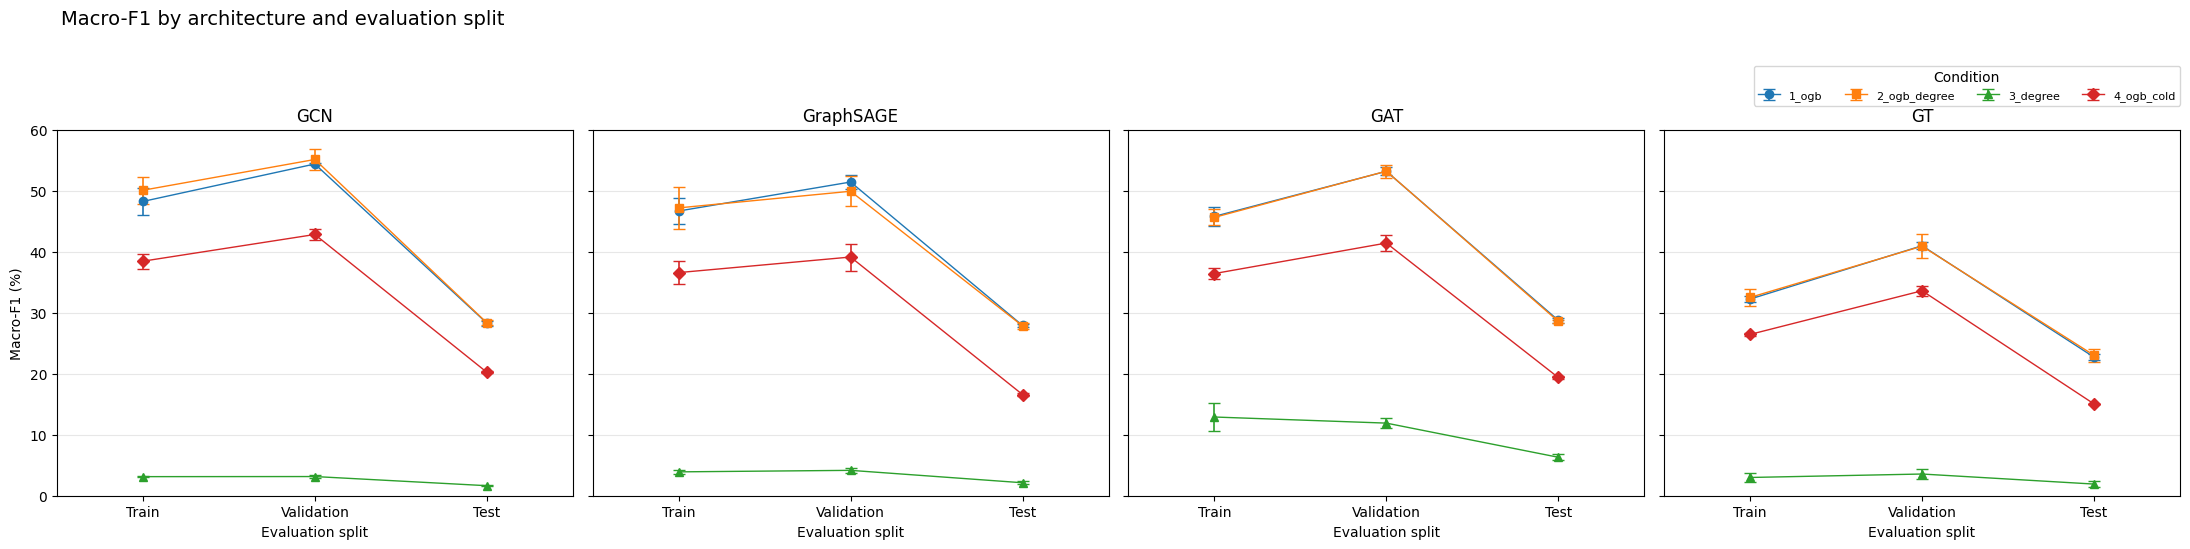

Points: seed means; error bars: +/- one sample standard deviation.
Saved figure to: /content/drive/MyDrive/CS5284_project/results/GNN_experiments/02_multi_seed/overall_performance/macro_f1_by_split.jpg


In [23]:
# Overall split line comparison: Macro-F1 (independent of the training cells).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

split_plot_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                       if (p / 'requirements.txt').is_file())
split_plot_dir = split_plot_root / 'results' / '1_gnn_ogb' / '02_multi_seed'
split_plot_metrics = pd.read_csv(split_plot_dir / 'all_metrics.csv')
scatter_metric = 'macro_f1_present'
scatter_architectures = ['GCN', 'GraphSAGE', 'GAT', 'GT']
scatter_conditions = ['1_ogb', '2_ogb_degree', '3_degree', '4_ogb_cold']
scatter_splits = ['train', 'valid', 'test']
scatter_summary = (split_plot_metrics.groupby(['architecture', 'condition', 'split'])[scatter_metric]
                   .agg(['mean', 'std', 'count']))
scatter_colours = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
scatter_markers = ['o', 's', '^', 'D']
fig, axes = plt.subplots(1, len(scatter_architectures), figsize=(22, 5.5), sharey=True)
for ax, architecture in zip(axes, scatter_architectures):
    for condition, colour, marker in zip(scatter_conditions, scatter_colours, scatter_markers):
        values = scatter_summary.loc[(architecture, condition)].reindex(scatter_splits)
        if values['mean'].isna().any():
            raise ValueError(f'Missing split scores for {architecture}/{condition}')
        ax.errorbar(np.arange(3), 100 * values['mean'],
                    yerr=100 * values['std'].fillna(0), fmt=marker,
                    color=colour, markersize=6, capsize=4, elinewidth=1.2,
                    linestyle='-', linewidth=1.0, label=condition)
    ax.set(title=architecture, xticks=np.arange(3),
           xticklabels=['Train', 'Validation', 'Test'], xlabel='Evaluation split',
           ylim=(0, 60), xlim=(-0.5, 2.5))
    ax.set_yticks(np.arange(0, 61, 10))
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
legend_handles, legend_labels = axes[0].get_legend_handles_labels()
axes[0].set_ylabel('Macro-F1 (%)')
fig.suptitle('Macro-F1 by architecture and evaluation split', fontsize=14, y=0.99, x=0.03, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.90])
# Anchor the legend just above the right subplot, rather than at the figure edge.
fig.legend(legend_handles, legend_labels, title='Condition',
           loc='lower right',
           bbox_to_anchor=(axes[-1].get_position().x1, axes[-1].get_position().y1 + 0.045),
           ncol=4, fontsize=8, frameon=True, borderaxespad=0)
scatter_output_dir = globals().get('DERIVED_DIR', split_plot_dir) / 'overall_performance'
scatter_output_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(scatter_output_dir / 'macro_f1_by_split.jpg', dpi=250, bbox_inches='tight')
scatter_summary.to_csv(scatter_output_dir / 'macro_f1_by_split_summary.csv')
plt.show()
print('Points: seed means; error bars: +/- one sample standard deviation.')
print('Saved figure to:', scatter_output_dir / 'macro_f1_by_split.jpg')


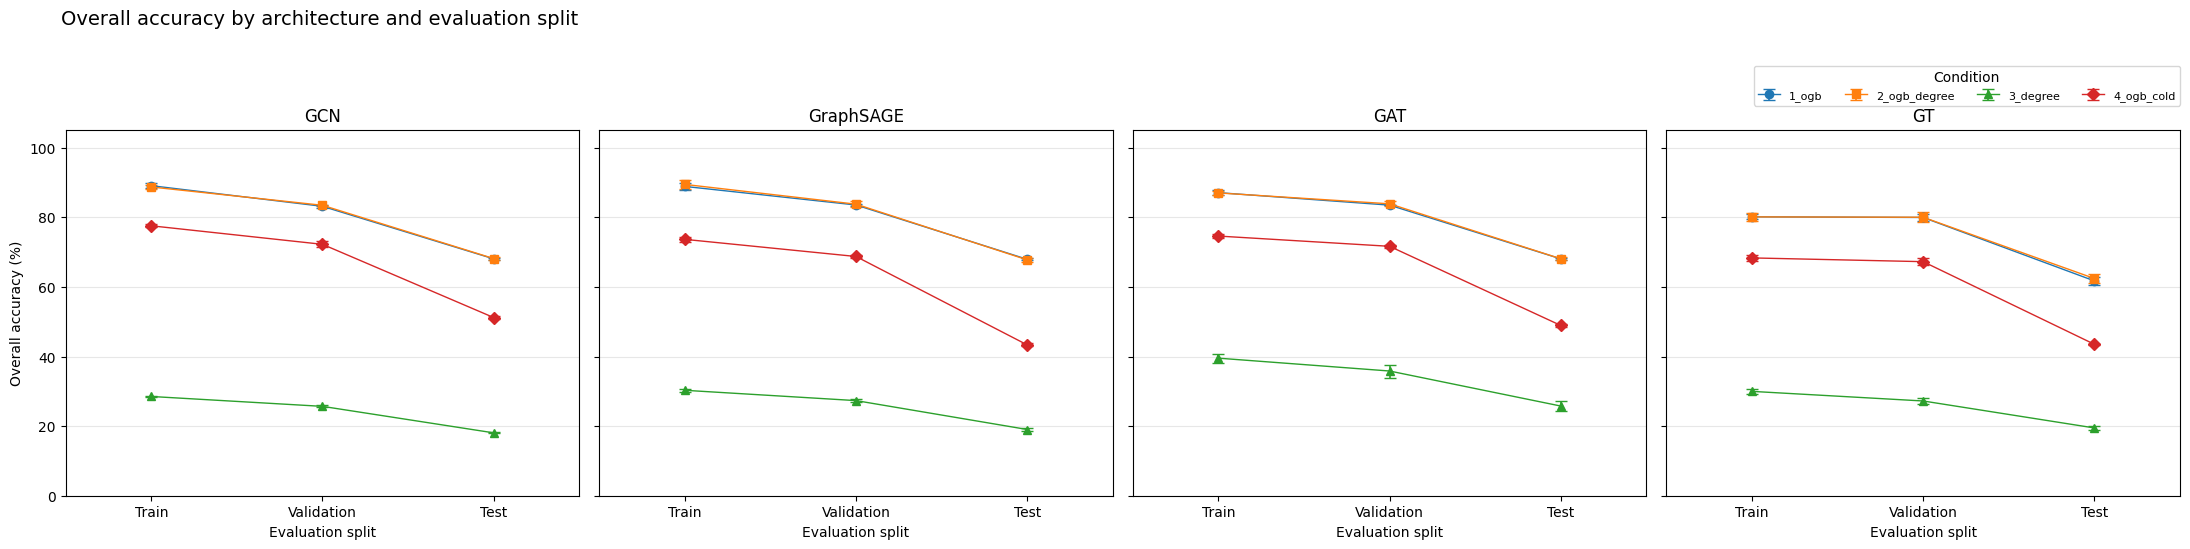

Points: seed means; error bars: +/- one sample standard deviation.
Saved figure to: /content/drive/MyDrive/CS5284_project/results/GNN_experiments/02_multi_seed/overall_performance/accuracy_by_split.jpg


In [24]:
# Overall split line comparison: Overall accuracy (independent of the training cells).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

split_plot_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                       if (p / 'requirements.txt').is_file())
split_plot_dir = split_plot_root / 'results' / '1_gnn_ogb' / '02_multi_seed'
split_plot_metrics = pd.read_csv(split_plot_dir / 'all_metrics.csv')
scatter_metric = 'accuracy'
scatter_architectures = ['GCN', 'GraphSAGE', 'GAT', 'GT']
scatter_conditions = ['1_ogb', '2_ogb_degree', '3_degree', '4_ogb_cold']
scatter_splits = ['train', 'valid', 'test']
scatter_summary = (split_plot_metrics.groupby(['architecture', 'condition', 'split'])[scatter_metric]
                   .agg(['mean', 'std', 'count']))
scatter_colours = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
scatter_markers = ['o', 's', '^', 'D']
fig, axes = plt.subplots(1, len(scatter_architectures), figsize=(22, 5.5), sharey=True)
for ax, architecture in zip(axes, scatter_architectures):
    for condition, colour, marker in zip(scatter_conditions, scatter_colours, scatter_markers):
        values = scatter_summary.loc[(architecture, condition)].reindex(scatter_splits)
        if values['mean'].isna().any():
            raise ValueError(f'Missing split scores for {architecture}/{condition}')
        ax.errorbar(np.arange(3), 100 * values['mean'],
                    yerr=100 * values['std'].fillna(0), fmt=marker,
                    color=colour, markersize=6, capsize=4, elinewidth=1.2,
                    linestyle='-', linewidth=1.0, label=condition)
    ax.set(title=architecture, xticks=np.arange(3),
           xticklabels=['Train', 'Validation', 'Test'], xlabel='Evaluation split',
           ylim=(0, 105), xlim=(-0.5, 2.5))
    ax.set_yticks(np.arange(0, 101, 20))
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
legend_handles, legend_labels = axes[0].get_legend_handles_labels()
axes[0].set_ylabel('Overall accuracy (%)')
fig.suptitle('Overall accuracy by architecture and evaluation split', fontsize=14, y=0.99, x=0.03, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.90])
# Anchor the legend just above the right subplot, rather than at the figure edge.
fig.legend(legend_handles, legend_labels, title='Condition',
           loc='lower right',
           bbox_to_anchor=(axes[-1].get_position().x1, axes[-1].get_position().y1 + 0.045),
           ncol=4, fontsize=8, frameon=True, borderaxespad=0)
scatter_output_dir = globals().get('DERIVED_DIR', split_plot_dir) / 'overall_performance'
scatter_output_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(scatter_output_dir / 'accuracy_by_split.jpg', dpi=250, bbox_inches='tight')
scatter_summary.to_csv(scatter_output_dir / 'accuracy_by_split_summary.csv')
plt.show()
print('Points: seed means; error bars: +/- one sample standard deviation.')
print('Saved figure to:', scatter_output_dir / 'accuracy_by_split.jpg')


## Validation results

In [25]:
validation_ranking = (
    all_metrics.query("split == 'valid' and condition != '4_ogb_cold'")
    .groupby(['architecture', 'condition'])[
        ['balanced_accuracy', 'macro_f1_present', 'accuracy']
    ]
    .agg(['mean', 'std', 'count'])
    .sort_values(('macro_f1_present', 'mean'), ascending=False)
)
display(validation_ranking.round(4))
print('Mean and sample standard deviation across seeds; count is the number of seed runs.')

balanced_accuracy               macro_f1_present  \
                                       mean     std count             mean   
architecture condition                                                       
GCN          2_ogb_degree            0.5479  0.0114     3           0.5521   
             1_ogb                   0.5465  0.0066     3           0.5447   
GAT          2_ogb_degree            0.5298  0.0171     3           0.5330   
             1_ogb                   0.5291  0.0125     3           0.5327   
GraphSAGE    1_ogb                   0.5065  0.0143     3           0.5151   
             2_ogb_degree            0.4994  0.0268     3           0.5000   
GT           1_ogb                   0.4126  0.0074     3           0.4105   
             2_ogb_degree            0.4140  0.0176     3           0.4098   
GAT          3_degree                0.1237  0.0107     3           0.1192   
GraphSAGE    3_degree                0.0578  0.0024     3           0.0417   
GT           3_degree                0.0575  0.0069     3           0.0356   
GCN          3_degree                0.0480  0.0017     3           0.0315   

                                        accuracy                
                              std count     mean     std count  
architecture condition                                          
GCN          2_ogb_degree  0.0167     3   0.8346  0.0006     3  
             1_ogb         0.0024     3   0.8316  0.0049     3  
GAT          2_ogb_degree  0.0106     3   0.8388  0.0068     3  
             1_ogb         0.0069     3   0.8350  0.0004     3  
GraphSAGE    1_ogb         0.0112     3   0.8355  0.0026     3  
             2_ogb_degree  0.0243     3   0.8378  0.0077     3  
GT           1_ogb         0.0059     3   0.7996  0.0100     3  
             2_ogb_degree  0.0200     3   0.8003  0.0140     3  
GAT          3_degree      0.0085     3   0.3584  0.0186     3  
GraphSAGE    3_degree      0.0037     3   0.2733  0.0040     3  
GT           3_degree      0.0090     3   0.2723  0.0081     3  
GCN          3_degree      0.0017     3   0.2568  0.0026     3

Mean and sample standard deviation across seeds; count is the number of seed runs.


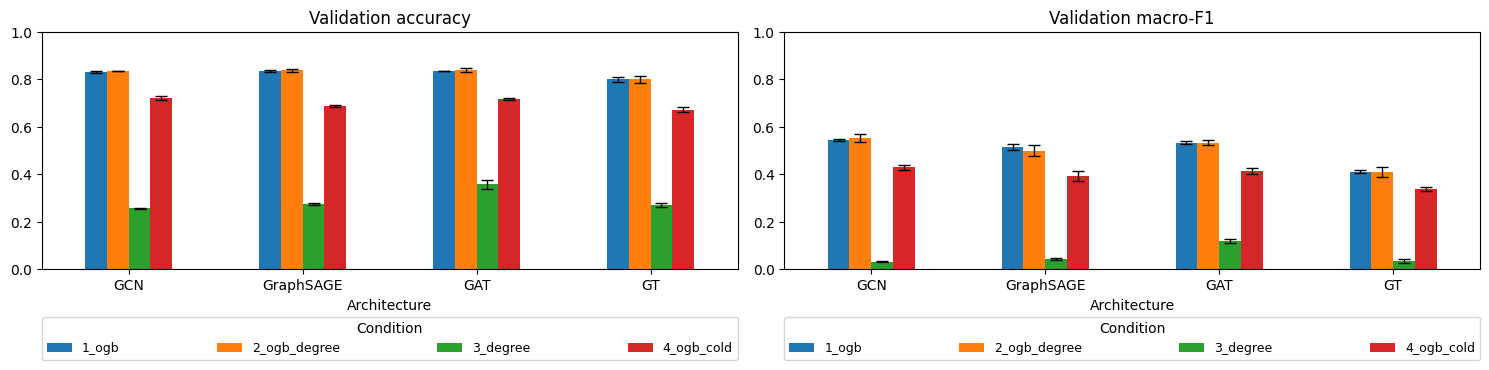

Bar heights show seed means; error bars show +/- one sample standard deviation.


In [26]:
# Plot the validation conditions used for model selection; cold start is evaluated separately.
architecture_order = ['GCN', 'GraphSAGE', 'GAT', 'GT']
validation_condition_order = ['1_ogb', '2_ogb_degree', '3_degree', '4_ogb_cold']
validation_plot_data = all_metrics.loc[
    (all_metrics['split'] == 'valid') &
    all_metrics['architecture'].isin(architecture_order) &
    all_metrics['condition'].isin(validation_condition_order)
]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric, title in zip(axes, ['accuracy', 'macro_f1_present'],
                            ['Validation accuracy', 'Validation macro-F1']):
    values = validation_plot_data.pivot_table(
        index='architecture', columns='condition', values=metric, aggfunc='mean'
    ).reindex(index=architecture_order, columns=validation_condition_order)
    deviations = validation_plot_data.pivot_table(
        index='architecture', columns='condition', values=metric, aggfunc='std'
    ).reindex(index=architecture_order, columns=validation_condition_order)
    values.plot.bar(ax=ax, yerr=deviations.fillna(0), capsize=4,
                    error_kw={'elinewidth': 1, 'capthick': 1})
    ax.set(title=title, ylim=(0, 1), xlabel='Architecture')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title='Condition', loc='upper left',
              bbox_to_anchor=(0, -0.20, 1, 0), mode='expand',
              ncol=len(ax.get_legend_handles_labels()[1]), borderaxespad=0, fontsize=9, frameon=True)
plt.tight_layout(rect=[0, 0.18, 1, 1])
plt.show()
print('Bar heights show seed means; error bars show +/- one sample standard deviation.')


## Test results

accuracy                 macro_f1_present  \
                               mean       std count             mean   
architecture condition                                                 
GAT          1_ogb         0.680629  0.002580     3         0.288035   
             2_ogb_degree  0.680832  0.003845     3         0.286248   
             3_degree      0.257659  0.015501     3         0.063154   
             4_ogb_cold    0.489248  0.003340     3         0.194146   
GCN          1_ogb         0.680646  0.002667     3         0.283469   
             2_ogb_degree  0.681415  0.005279     3         0.284026   
             3_degree      0.180660  0.001673     3         0.016469   
             4_ogb_cold    0.511927  0.005003     3         0.202786   
GT           1_ogb         0.617318  0.011682     3         0.227469   
             2_ogb_degree  0.624215  0.013988     3         0.230587   
             3_degree      0.194763  0.006067     3         0.019128   
             4_ogb_cold    0.435122  0.000760     3         0.150738   
GraphSAGE    1_ogb         0.679251  0.002816     3         0.279531   
             2_ogb_degree  0.677732  0.006264     3         0.278857   
             3_degree      0.190295  0.003097     3         0.021300   
             4_ogb_cold    0.433347  0.004291     3         0.166105   

                                          macro_f1_47                  \
                                std count        mean       std count   
architecture condition                                                  
GAT          1_ogb         0.004099     3    0.245136  0.003489     3   
             2_ogb_degree  0.002611     3    0.243616  0.002222     3   
             3_degree      0.004834     3    0.053748  0.004114     3   
             4_ogb_cold    0.001966     3    0.165231  0.001673     3   
GCN          1_ogb         0.004219     3    0.241250  0.003591     3   
             2_ogb_degree  0.004384     3    0.241724  0.003731     3   
             3_degree      0.001242     3    0.014016  0.001057     3   
             4_ogb_cold    0.001798     3    0.172584  0.001530     3   
GT           1_ogb         0.005397     3    0.193591  0.004593     3   
             2_ogb_degree  0.010858     3    0.196245  0.009240     3   
             3_degree      0.004856     3    0.016279  0.004133     3   
             4_ogb_cold    0.000636     3    0.128288  0.000541     3   
GraphSAGE    1_ogb         0.002854     3    0.237899  0.002429     3   
             2_ogb_degree  0.004506     3    0.237325  0.003835     3   
             3_degree      0.002066     3    0.018127  0.001758     3   
             4_ogb_cold    0.002592     3    0.141366  0.002206     3   

                          balanced_accuracy                  
                                       mean       std count  
architecture condition                                       
GAT          1_ogb                 0.311209  0.002129     3  
             2_ogb_degree          0.310618  0.000561     3  
             3_degree              0.075656  0.007034     3  
             4_ogb_cold            0.209436  0.002094     3  
GCN          1_ogb                 0.307736  0.003449     3  
             2_ogb_degree          0.308549  0.004842     3  
             3_degree              0.030219  0.001147     3  
             4_ogb_cold            0.219794  0.000776     3  
GT           1_ogb                 0.254833  0.001582     3  
             2_ogb_degree          0.258888  0.006303     3  
             3_degree              0.038359  0.004272     3  
             4_ogb_cold            0.170830  0.000513     3  
GraphSAGE    1_ogb                 0.304352  0.003296     3  
             2_ogb_degree          0.305672  0.007541     3  
             3_degree              0.036817  0.002208     3  
             4_ogb_cold            0.176763  0.002967     3

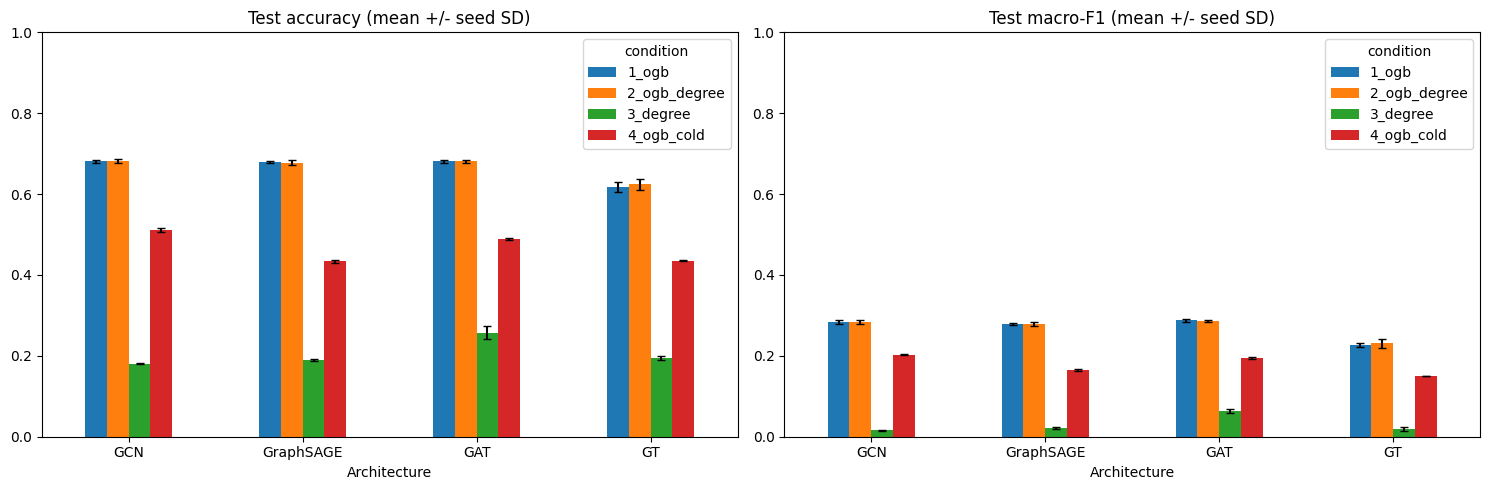

Saved repeated-seed metrics to: /content/drive/MyDrive/CS5284_project/results/GNN_experiments/02_multi_seed


In [27]:
all_test.to_csv(DERIVED_DIR / 'test_comparison.csv', index=False)
summary = seed_summary(all_metrics, ['architecture', 'condition', 'split'],
                       ['accuracy', 'macro_f1_present', 'macro_f1_47', 'balanced_accuracy'])
summary.to_csv(DERIVED_DIR / 'seed_summary.csv')
display(summary.xs('test', level='split'))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric, title in zip(axes, ['accuracy', 'macro_f1_present'], ['Test accuracy', 'Test macro-F1']):
    means = all_test.pivot_table(index='architecture', columns='condition', values=metric, aggfunc='mean')
    deviations = all_test.pivot_table(index='architecture', columns='condition', values=metric, aggfunc='std')
    order = [a for a in ['GCN', 'GraphSAGE', 'GAT', 'GT'] if a in means.index]
    means, deviations = means.reindex(order), deviations.reindex(order)
    means.plot.bar(ax=ax, yerr=deviations.fillna(0), capsize=3)
    ax.set(title=title + ' (mean +/- seed SD)', ylim=(0, 1), xlabel='Architecture')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
print('Saved repeated-seed metrics to:', DERIVED_DIR if WRITE_OUTPUTS else 'nothing (unchanged)')


## Paired seed comparisons: validation and test macro-F1

This section runs directly from `results/1_gnn_ogb/02_multi_seed/all_metrics.csv`, without training or rerunning earlier cells. Select the **observed leader using mean validation macro-F1** among the four main architectures (GCN, GraphSAGE, GAT, GT) and three trained feature conditions; retain that same reference for test comparisons.

For each matching seed, calculate **candidate minus reference**. The table reports the mean difference and a nominal 95% paired t-interval: `mean_difference +/- t(0.975, n-1) * SD(differences) / sqrt(n)`. Negative values favour the reference. An interval crossing zero does not establish equivalence; a wholly negative interval provides only nominal evidence favouring the reference.

**Interpret cautiously:** three seeds give two degrees of freedom and a t multiplier of about 4.303. Normality of seed differences cannot be assessed reliably. Matching seed IDs does not mean different architectures use identical initial weights or dropout masks. These intervals describe training variability on fixed evaluation products, not uncertainty from sampled products. Validation-leader selection and multiple comparisons make the intervals exploratory; they are not selection-adjusted or simultaneous confidence statements. Test results do not change the selected leader.

Cold-start rows are excluded from leader selection and the main ranking. A separate paired comparison below contrasts each architecture's cold-start predictions with its own OGB-only baseline.


In [28]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t
from IPython.display import display

paired_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                   if (p / 'requirements.txt').is_file())
paired_result_dir = paired_root / 'results' / '1_gnn_ogb' / '02_multi_seed'
paired_output_dir = globals().get('DERIVED_DIR', paired_result_dir) / 'paired_comparisons'
paired_output_dir.mkdir(parents=True, exist_ok=True)
paired_data = pd.read_csv(paired_result_dir / 'all_metrics.csv')
paired_architectures = ['GCN', 'GraphSAGE', 'GAT', 'GT']
paired_conditions = ['1_ogb', '2_ogb_degree', '3_degree']
paired_data = paired_data.loc[paired_data.architecture.isin(paired_architectures)].copy()
keys = ['architecture', 'condition', 'split', 'seed']
if paired_data.duplicated(keys).any():
    raise ValueError('Duplicate seed-level metrics found; resolve duplicates before comparing.')
selection = paired_data.loc[(paired_data.split == 'valid') & paired_data.condition.isin(paired_conditions) &
                            paired_data.architecture.isin(paired_architectures)]
seed_sets = selection.groupby(['architecture', 'condition'])['seed'].apply(lambda x: frozenset(x))
expected_candidates = len(paired_architectures) * len(paired_conditions)
if len(seed_sets) != expected_candidates or len(set(seed_sets)) != 1:
    raise ValueError(f'Expected all {expected_candidates} trained candidates with exactly matching validation seeds.')
if len(seed_sets.iloc[0]) < 2:
    raise ValueError('At least two matched seeds are required for t-intervals; three are configured.')
leader_ranking = (selection.groupby(['architecture', 'condition'])['macro_f1_present'].mean()
                  .sort_values(ascending=False, kind='stable'))
leader_architecture, leader_condition = leader_ranking.index[0]
print(f'Observed validation leader: {leader_architecture} / {leader_condition}; '
      f'mean macro-F1 = {leader_ranking.iloc[0]:.4f}')
leader_ranking.rename('mean_validation_macro_f1').to_csv(paired_output_dir / 'validation_leader_ranking.csv')


def pair_scores(candidate, reference, metadata):
    candidate = candidate.set_index('seed')['macro_f1_present'].sort_index()
    reference = reference.set_index('seed')['macro_f1_present'].sort_index()
    if not candidate.index.equals(reference.index):
        raise ValueError(f'Unmatched seeds for {metadata}')
    differences = candidate - reference
    if not np.isfinite(differences.to_numpy()).all():
        raise ValueError('Non-finite macro-F1 scores cannot be compared.')
    n_pairs = len(differences)
    if n_pairs < 2:
        raise ValueError('At least two pairs are required.')
    mean_difference = float(differences.mean())
    sd_difference = float(differences.std(ddof=1))
    standard_error = sd_difference / np.sqrt(n_pairs)
    t_critical = float(student_t.ppf(0.975, df=n_pairs - 1))
    margin = t_critical * standard_error
    lower, upper = mean_difference - margin, mean_difference + margin
    status = ('CI below zero' if upper < 0 else 'CI above zero' if lower > 0
              else 'CI includes zero')
    summary_row = dict(**metadata, n_pairs=n_pairs, candidate_mean=float(candidate.mean()),
                       reference_mean=float(reference.mean()), mean_difference=mean_difference,
                       sd_difference=sd_difference, standard_error=standard_error,
                       ci95_lower=lower, ci95_upper=upper, t_critical=t_critical,
                       nominal_interval=status)
    seed_rows = [dict(**metadata, seed=int(seed), candidate_score=float(candidate.loc[seed]),
                      reference_score=float(reference.loc[seed]), difference=float(differences.loc[seed]))
                 for seed in differences.index]
    return summary_row, seed_rows


def plot_paired_intervals(table, title, filename):
    splits = [split for split in ['valid', 'test'] if split in set(table['split'])]
    fig, axes = plt.subplots(1, len(splits), figsize=(max(10, 8 * len(splits)), 6), squeeze=False)
    for ax, split in zip(axes.flat, splits):
        frame = (table.loc[table.split == split]
                 .sort_values('candidate_mean', ascending=False, kind='stable').reset_index(drop=True))
        positions = np.arange(len(frame))
        errors = np.vstack([frame.mean_difference - frame.ci95_lower,
                            frame.ci95_upper - frame.mean_difference])
        ax.errorbar(positions, frame.mean_difference, yerr=errors,
                    fmt='o', capsize=4, color='steelblue', ecolor='steelblue')
        ax.axhline(0, color='black', linestyle='--', linewidth=1)
        ax.set(xticks=positions, xticklabels=frame.label,
               ylabel='Macro-F1 difference (candidate - reference)',
               xlabel='Architecture-condition (descending mean macro-F1)',
               title='Validation' if split == 'valid' else 'Test')
        ax.tick_params(axis='x', rotation=35)
        for label in ax.get_xticklabels():
            label.set_horizontalalignment('right')
        ax.grid(axis='y', alpha=0.2)
    fig.suptitle(title + '\nNominal 95% paired t-intervals across matching seeds')
    plt.tight_layout()
    fig.savefig(paired_output_dir / filename, dpi=200, bbox_inches='tight')
    plt.show()


paired_split_tables = {}
paired_split_differences = {}


def run_paired_split(split):
    comparison_rows, seed_rows = [], []
    reference = paired_data.loc[(paired_data.split == split) &
        (paired_data.architecture == leader_architecture) & (paired_data.condition == leader_condition)]
    for architecture in paired_architectures:
        for condition in paired_conditions:
            if (architecture, condition) == (leader_architecture, leader_condition):
                continue  # Reference compared with itself has no uncertainty to estimate.
            candidate = paired_data.loc[(paired_data.split == split) &
                (paired_data.architecture == architecture) & (paired_data.condition == condition)]
            metadata = dict(split=split, architecture=architecture, condition=condition,
                            reference_architecture=leader_architecture, reference_condition=leader_condition,
                            label=f'{architecture} / {condition}')
            row, differences = pair_scores(candidate, reference, metadata)
            comparison_rows.append(row)
            seed_rows.extend(differences)
    result = (pd.DataFrame(comparison_rows)
              .sort_values('candidate_mean', ascending=False, kind='stable').reset_index(drop=True))
    differences = pd.DataFrame(seed_rows)
    paired_split_tables[split] = result
    paired_split_differences[split] = differences
    result.to_csv(paired_output_dir / f'{split}_leader_paired_comparison.csv', index=False)
    differences.to_csv(paired_output_dir / f'{split}_leader_seed_differences.csv', index=False)
    # Refresh combined files with the splits evaluated in this session.
    pd.concat(paired_split_tables.values(), ignore_index=True).to_csv(
        paired_output_dir / 'leader_paired_comparison.csv', index=False)
    pd.concat(paired_split_differences.values(), ignore_index=True).to_csv(
        paired_output_dir / 'leader_seed_differences.csv', index=False)
    print(f'{split}: sorted by candidate mean macro-F1, highest first.')
    print(f'Reference: {leader_architecture} / {leader_condition}; same validation-selected reference for both splits.')
    display(result[['label', 'n_pairs', 'candidate_mean', 'reference_mean', 'mean_difference',
                    'sd_difference', 'ci95_lower', 'ci95_upper', 'nominal_interval']].round(4))
    plot_paired_intervals(result, f'Reference: {leader_architecture} / {leader_condition}',
                         f'{split}_leader_intervals.jpg')
    return result


Observed validation leader: GCN / 2_ogb_degree; mean macro-F1 = 0.5521


### Validation paired comparisons

Candidates are sorted by mean validation macro-F1, highest first. The observed reference is omitted from its own comparison. Run the shared paired setup above first.


valid: sorted by candidate mean macro-F1, highest first.
Reference: GCN / 2_ogb_degree; same validation-selected reference for both splits.


,label,n_pairs,candidate_mean,reference_mean,mean_difference,sd_difference,ci95_lower,ci95_upper,nominal_interval
0,GCN / 1_ogb,3,0.5447,0.5521,-0.0074,0.0179,-0.0519,0.0371,CI includes zero
1,GAT / 2_ogb_degree,3,0.5330,0.5521,-0.0192,0.0225,-0.0751,0.0367,CI includes zero
2,GAT / 1_ogb,3,0.5327,0.5521,-0.0194,0.0233,-0.0774,0.0386,CI includes zero
3,GraphSAGE / 1_ogb,3,0.5151,0.5521,-0.0370,0.0280,-0.1065,0.0324,CI includes zero
4,GraphSAGE / 2_ogb_degree,3,0.5000,0.5521,-0.0522,0.0359,-0.1414,0.0370,CI includes zero
5,GT / 1_ogb,3,0.4105,0.5521,-0.1416,0.0196,-0.1902,-0.0930,CI below zero
6,GT / 2_ogb_degree,3,0.4098,0.5521,-0.1424,0.0113,-0.1705,-0.1143,CI below zero
7,GAT / 3_degree,3,0.1192,0.5521,-0.4329,0.0200,-0.4825,-0.3833,CI below zero
8,GraphSAGE / 3_degree,3,0.0417,0.5521,-0.5105,0.0169,-0.5525,-0.4685,CI below zero
9,GT / 3_degree,3,0.0356,0.5521,-0.5165,0.0249,-0.5784,-0.4546,CI below zero


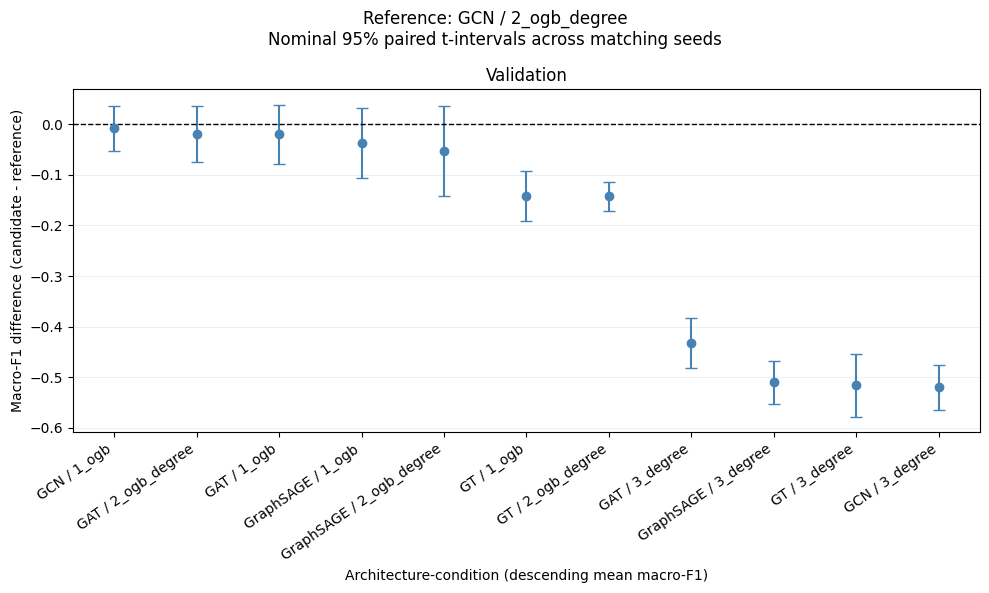

In [29]:
validation_paired_comparison = run_paired_split('valid')


### Test paired comparisons

Candidates are sorted by mean test macro-F1, highest first. The reference remains the validation-selected leader; this display order does not select a new model. Run the shared paired setup above first; running the validation comparison cell is optional.


test: sorted by candidate mean macro-F1, highest first.
Reference: GCN / 2_ogb_degree; same validation-selected reference for both splits.


,label,n_pairs,candidate_mean,reference_mean,mean_difference,sd_difference,ci95_lower,ci95_upper,nominal_interval
0,GAT / 1_ogb,3,0.2880,0.284,0.0040,0.0056,-0.0098,0.0178,CI includes zero
1,GAT / 2_ogb_degree,3,0.2862,0.284,0.0022,0.0066,-0.0142,0.0186,CI includes zero
2,GCN / 1_ogb,3,0.2835,0.284,-0.0006,0.0031,-0.0082,0.0071,CI includes zero
3,GraphSAGE / 1_ogb,3,0.2795,0.284,-0.0045,0.0069,-0.0217,0.0127,CI includes zero
4,GraphSAGE / 2_ogb_degree,3,0.2789,0.284,-0.0052,0.0057,-0.0194,0.0090,CI includes zero
5,GT / 2_ogb_degree,3,0.2306,0.284,-0.0534,0.0067,-0.0700,-0.0369,CI below zero
6,GT / 1_ogb,3,0.2275,0.284,-0.0566,0.0078,-0.0758,-0.0373,CI below zero
7,GAT / 3_degree,3,0.0632,0.284,-0.2209,0.0076,-0.2399,-0.2019,CI below zero
8,GraphSAGE / 3_degree,3,0.0213,0.284,-0.2627,0.0057,-0.2769,-0.2485,CI below zero
9,GT / 3_degree,3,0.0191,0.284,-0.2649,0.0084,-0.2858,-0.2440,CI below zero


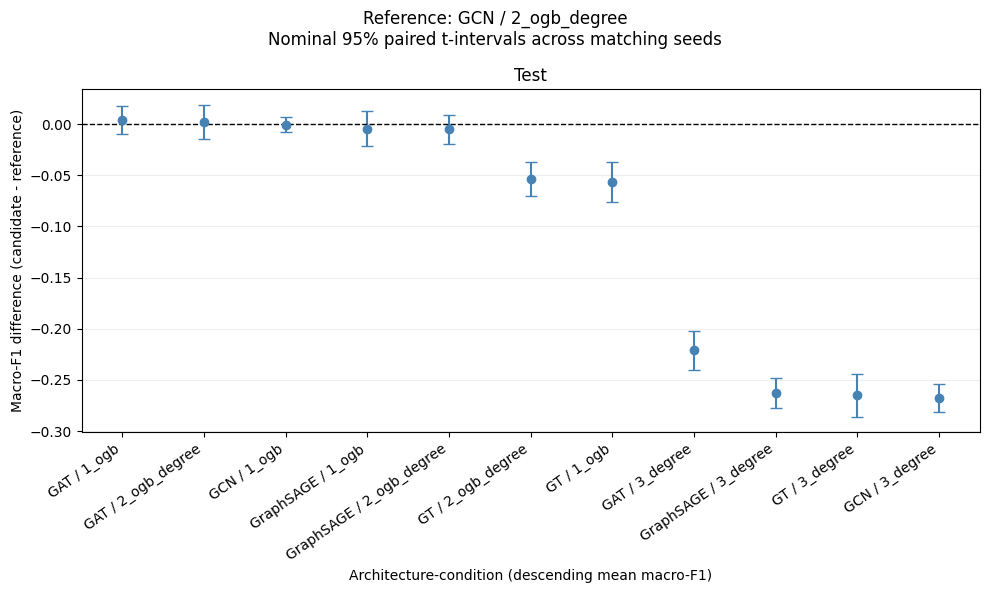

In [30]:
test_paired_comparison = run_paired_split('test')


### Paired cold-start robustness checks

Each cold-start score is paired with the same architecture and seed's OGB-only score (GCN, GraphSAGE, GAT and GT). Negative differences indicate a drop after removing test-incident connections. Validation cold-start results are descriptive only and do not select a new checkpoint or leader.


,split,architecture,n_pairs,mean_difference,ci95_lower,ci95_upper,nominal_interval
0,test,GCN,3,-0.0807,-0.0868,-0.0746,CI below zero
1,test,GAT,3,-0.0939,-0.1023,-0.0855,CI below zero
2,test,GraphSAGE,3,-0.1134,-0.1251,-0.1018,CI below zero
3,test,GT,3,-0.0767,-0.0886,-0.0649,CI below zero
4,valid,GCN,3,-0.1158,-0.1391,-0.0925,CI below zero
5,valid,GAT,3,-0.1178,-0.1401,-0.0955,CI below zero
6,valid,GraphSAGE,3,-0.1232,-0.1528,-0.0936,CI below zero
7,valid,GT,3,-0.0739,-0.0809,-0.0670,CI below zero


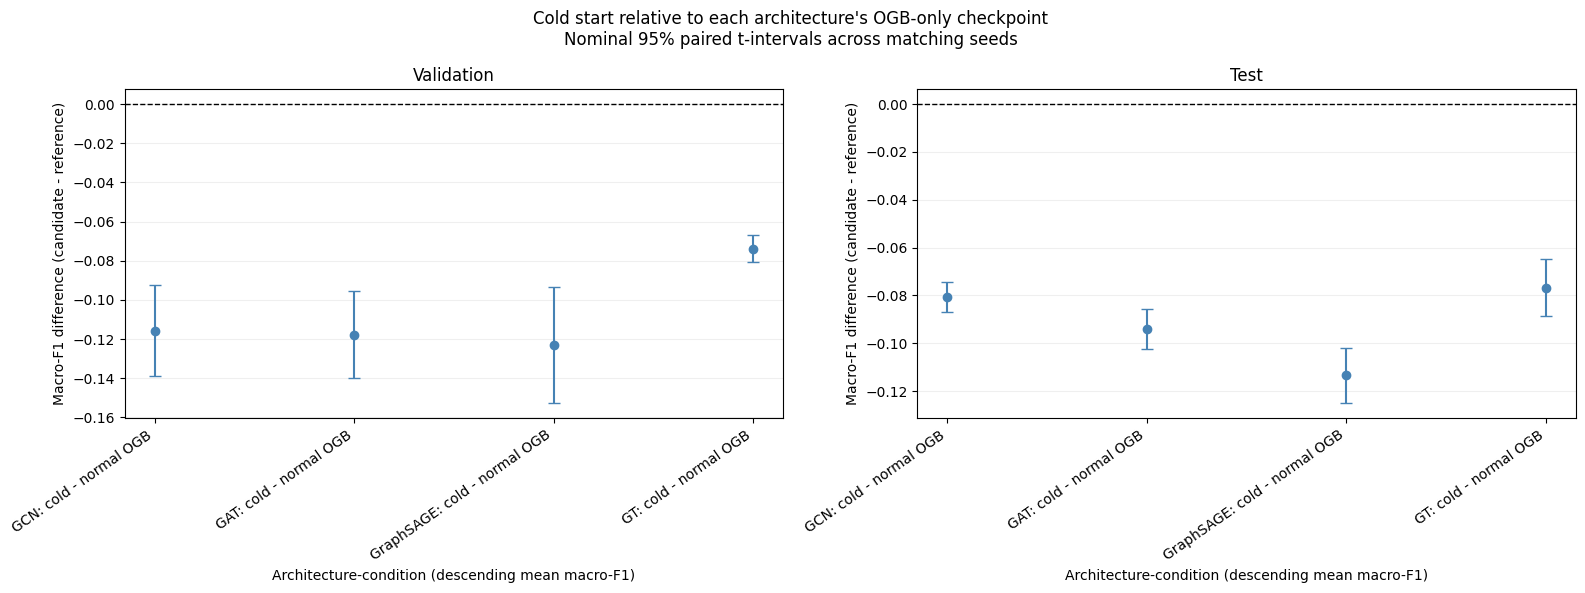

In [31]:
cold_rows, cold_seed_rows = [], []
cold_architectures = paired_architectures
for split in ['valid', 'test']:
    for architecture in cold_architectures:
        candidate = paired_data.loc[(paired_data.split == split) &
            (paired_data.architecture == architecture) & (paired_data.condition == '4_ogb_cold')]
        reference = paired_data.loc[(paired_data.split == split) &
            (paired_data.architecture == architecture) & (paired_data.condition == '1_ogb')]
        metadata = dict(split=split, architecture=architecture, condition='4_ogb_cold',
                        reference_architecture=architecture, reference_condition='1_ogb',
                        label=f'{architecture}: cold - normal OGB')
        row, differences = pair_scores(candidate, reference, metadata)
        cold_rows.append(row); cold_seed_rows.extend(differences)
cold_paired_comparison = pd.DataFrame(cold_rows).sort_values(
    ['split', 'candidate_mean'], ascending=[True, False], kind='stable').reset_index(drop=True)
cold_paired_comparison.to_csv(paired_output_dir / 'cold_start_paired_comparison.csv', index=False)
pd.DataFrame(cold_seed_rows).to_csv(paired_output_dir / 'cold_start_seed_differences.csv', index=False)
display(cold_paired_comparison[['split', 'architecture', 'n_pairs', 'mean_difference',
                               'ci95_lower', 'ci95_upper', 'nominal_interval']].round(4))
plot_paired_intervals(cold_paired_comparison, "Cold start relative to each architecture's OGB-only checkpoint",
                     'validation_test_cold_intervals.jpg')


# Supplementary diagnostics for category split differences

These cells use the predictions and diagnostic CSVs produced by the new runs; no retraining is needed after these artifacts exist. They compare:

- **Validation versus test:** per-category precision, recall, F1, support, training support and recall intervals. No-support recall intervals are undefined, rather than zero-confidence observations.
- **Seen versus unseen categories:** recompute scores after filtering products by true category. Predictions into excluded categories remain errors; predictions are never forced into the retained label set.
- **Training support groups:** 0, 1-9, 10-99, 100-999 and 1000+ training products. These descriptive thresholds use training counts only. Group macro-F1 and balanced accuracy weight supported categories equally; group accuracy weights products.
- **Common category mixture:** validation/test confusion matrices are reweighted to a uniform distribution over categories present in BOTH splits. This is a supplementary comparison, not a replacement benchmark. It changes the question, and does not eliminate differences between products within categories.

**Uncertainty:** 95% Wilson recall intervals are approximate marginal binomial intervals conditional on a fitted model. They assume independent evaluation outcomes; connected products can violate that assumption, so interpret them descriptively. Multiple seeds measure training variability separately; never pool repeated predictions of the same product as independent samples. Intervals do not establish causality or correct sparse categories. Checkpoints and hyperparameters still use validation data only.


Full versus seen/unseen test evaluation (recomputed precision and F1):


accuracy                 macro_f1_present  \
                                      mean       std count             mean   
architecture condition    group                                               
GAT          1_ogb        full    0.680629  0.002580     3         0.288035   
                          seen    0.696347  0.002639     3         0.381432   
                          unseen  0.000000  0.000000     3         0.000000   
             2_ogb_degree full    0.680832  0.003845     3         0.286248   
                          seen    0.696555  0.003934     3         0.378399   
                          unseen  0.000000  0.000000     3         0.000000   
             3_degree     full    0.257659  0.015501     3         0.063154   
                          seen    0.263609  0.015859     3         0.082310   
                          unseen  0.000000  0.000000     3         0.000000   
             4_ogb_cold   full    0.489248  0.003340     3         0.194146   
                          seen    0.500547  0.003418     3         0.255003   
                          unseen  0.000000  0.000000     3         0.000000   
GCN          1_ogb        full    0.680646  0.002667     3         0.283469   
                          seen    0.696365  0.002729     3         0.374675   
                          unseen  0.000000  0.000000     3         0.000000   
             2_ogb_degree full    0.681415  0.005279     3         0.284026   
                          seen    0.697151  0.005401     3         0.375327   
                          unseen  0.000000  0.000000     3         0.000000   
             3_degree     full    0.180660  0.001673     3         0.016469   
                          seen    0.184832  0.001712     3         0.021493   
                          unseen  0.000000  0.000000     3         0.000000   
             4_ogb_cold   full    0.511927  0.005003     3         0.202786   
                          seen    0.523749  0.005119     3         0.266015   
                          unseen  0.000000  0.000000     3         0.000000   
GT           1_ogb        full    0.617318  0.011682     3         0.227469   
                          seen    0.631574  0.011952     3         0.296846   
                          unseen  0.000000  0.000000     3         0.000000   
             2_ogb_degree full    0.624215  0.013988     3         0.230587   
                          seen    0.638631  0.014311     3         0.301490   
                          unseen  0.000000  0.000000     3         0.000000   
             3_degree     full    0.194763  0.006067     3         0.019128   
                          seen    0.199261  0.006207     3         0.025013   
                          unseen  0.000000  0.000000     3         0.000000   
             4_ogb_cold   full    0.435122  0.000760     3         0.150738   
                          seen    0.445170  0.000777     3         0.196833   
                          unseen  0.000000  0.000000     3         0.000000   
GraphSAGE    1_ogb        full    0.679251  0.002816     3         0.279531   
                          seen    0.694938  0.002882     3         0.368688   
                          unseen  0.000000  0.000000     3         0.000000   
             2_ogb_degree full    0.677732  0.006264     3         0.278857   
                          seen    0.693384  0.006409     3         0.366978   
                          unseen  0.000000  0.000000     3         0.000000   
             3_degree     full    0.190295  0.003097     3         0.021300   
                          seen    0.194689  0.003169     3         0.027789   
                          unseen  0.000000  0.000000     3         0.000000   
             4_ogb_cold   full    0.433347  0.004291     3         0.166105   
                          seen    0.443354  0.004390     3         0.217310   
                          unseen  0.000000  0.000000     3         0.000000   

    

Training-support groups:


accuracy                  \
                                                      mean       std count   
architecture condition  group                                                
GAT          1_ogb      train_support_0 (unseen)  0.000000  0.000000     3   
                        train_support_1-9         0.000000  0.000000     3   
                        train_support_10-99       0.028357  0.012270     3   
                        train_support_100-999     0.672785  0.003479     3   
                        train_support_1000+       0.881112  0.002428     3   
...                                                    ...       ...   ...   
GraphSAGE    4_ogb_cold train_support_0 (unseen)  0.000000  0.000000     3   
                        train_support_1-9         0.000000  0.000000     3   
                        train_support_10-99       0.006487  0.004434     3   
                        train_support_100-999     0.358964  0.009329     3   
                        train_support_1000+       0.641462  0.008162     3   

                                                 macro_f1_present            \
                                                             mean       std   
architecture condition  group                                                 
GAT          1_ogb      train_support_0 (unseen)         0.000000  0.000000   
                        train_support_1-9                0.000000  0.000000   
                        train_support_10-99              0.153707  0.011484   
                        train_support_100-999            0.655212  0.003063   
                        train_support_1000+              0.894454  0.001769   
...                                                           ...       ...   
GraphSAGE    4_ogb_cold train_support_0 (unseen)         0.000000  0.000000   
                        train_support_1-9                0.000000  0.000000   
                        train_support_10-99              0.053342  0.014431   
                        train_support_100-999            0.366239  0.006887   
                        train_support_1000+              0.687478  0.014099   

                                                       balanced_accuracy  \
                                                 count              mean   
architecture condition  group                                              
GAT          1_ogb      train_support_0 (unseen)     3          0.000000   
                        train_support_1-9            3          0.000000   
                        train_support_10-99          3          0.102045   
                        train_support_100-999        3          0.619882   
                        train_support_1000+          3          0.859094   
...                                                ...               ...   
GraphSAGE    4_ogb_cold train_support_0 (unseen)     3          0.000000   
                        train_support_1-9            3          0.000000   
                        train_support_10-99          3          0.034591   
                        train_support_100-999        3          0.309535   
                        train_support_1000+          3          0.622789   

                                                                  
                                                       std count  
architecture condition  group                                     
GAT          1_ogb      train_support_0 (unseen)  0.000000     3  
                        train_support_1-9         0.000000     3  
                        train_support_10-99       0.008323     3  
                        train_support_100-999     0.001649     3  
                        train_support_1000+       0.002819     3  
...                                                    ...   ...  
GraphSAGE    4_ogb_cold train_support_0 (unseen)  0.000000     3  
                        train_support_1-9         0.000000     3  
                        train_support_10-99     

Validation/test after fixing the category mixture (common categories only):


accuracy                 macro_f1_present  \
                                     mean       std count             mean   
architecture condition    split                                              
GAT          1_ogb        test   0.478783  0.003275     3         0.403116   
                          valid  0.529059  0.012531     3         0.472575   
             2_ogb_degree test   0.477873  0.000862     3         0.401199   
                          valid  0.529784  0.017147     3         0.470973   
             3_degree     test   0.116393  0.010821     3         0.078507   
                          valid  0.123656  0.010734     3         0.091137   
             4_ogb_cold   test   0.322209  0.003221     3         0.269316   
                          valid  0.409023  0.013748     3         0.353056   
GCN          1_ogb        test   0.473441  0.005306     3         0.394747   
                          valid  0.546504  0.006604     3         0.490520   
             2_ogb_degree test   0.474691  0.007449     3         0.396374   
                          valid  0.547918  0.011376     3         0.492118   
             3_degree     test   0.046490  0.001764     3         0.013344   
                          valid  0.047960  0.001690     3         0.014813   
             4_ogb_cold   test   0.338145  0.001194     3         0.279619   
                          valid  0.421134  0.007770     3         0.372328   
GT           1_ogb        test   0.392051  0.002434     3         0.289606   
                          valid  0.412604  0.007419     3         0.324661   
             2_ogb_degree test   0.398289  0.009697     3         0.295593   
                          valid  0.413991  0.017568     3         0.324460   
             3_degree     test   0.059014  0.006572     3         0.017511   
                          valid  0.057459  0.006873     3         0.017277   
             4_ogb_cold   test   0.262815  0.000790     3         0.189344   
                          valid  0.335884  0.008416     3         0.265553   
GraphSAGE    1_ogb        test   0.468234  0.005070     3         0.385310   
                          valid  0.506514  0.014277     3         0.444661   
             2_ogb_degree test   0.470265  0.011602     3         0.385115   
                          valid  0.499368  0.026764     3         0.421750   
             3_degree     test   0.056642  0.003397     3         0.019731   
                          valid  0.057837  0.002371     3         0.022476   
             4_ogb_cold   test   0.271943  0.004564     3         0.228090   
                          valid  0.382727  0.019384     3         0.331734   

                                                balanced_accuracy            \
                                      std count              mean       std   
architecture condition    split                                               
GAT          1_ogb        test   0.004240     3          0.478783  0.003275   
                          valid  0.016010     3          0.529059  0.012531   
             2_ogb_degree test   0.001550     3          0.477873  0.000862   
                          valid  0.019031     3          0.529784  0.017147   
             3_degree     test   0.005437     3          0.116393  0.010821   
                          valid  0.005658     3          0.123656  0.010734   
             4_ogb_cold   test   0.003721     3          0.322209  0.003221   
                          valid  0.023795     3          0.409023  0.013748   
GCN          1_ogb        test   0.009223     3          0.473441  0.005306   
                          valid  0.010743     3          0.546504  0.006604   
             2_ogb_degree test   0.010794     3          0.474691  0.007449   
                          valid  0.019169     3          0.547918  0.011376   
             3_degree     test   0.001536     3          0.046490  0.001764   
                          valid  0.001

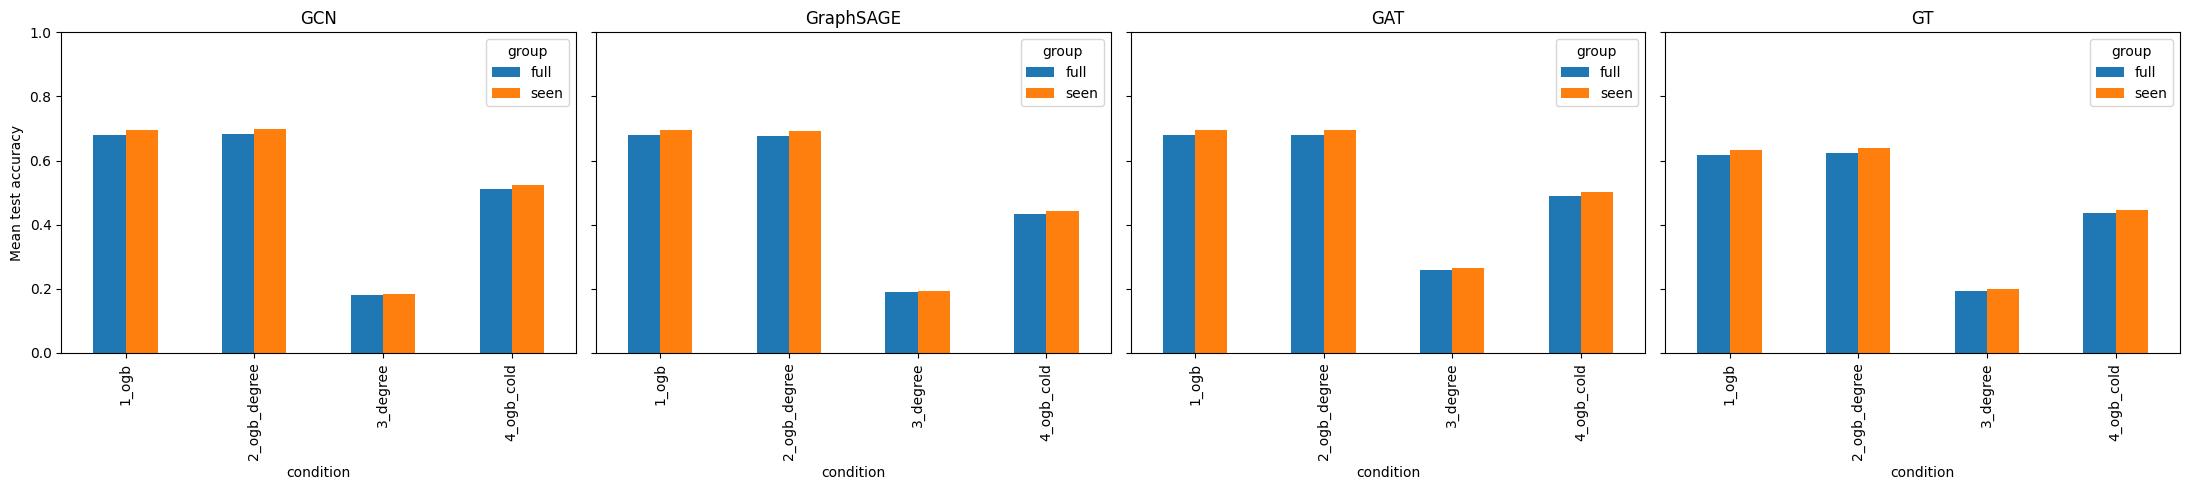

Example category comparison: GT, OGB-only, primary seed


,category_id,category,support_valid,predicted_support_valid,correct_valid,precision_valid,recall_valid,f1_valid,recall_ci95_lower_valid,recall_ci95_upper_valid,...,recall_test,f1_test,recall_ci95_lower_test,recall_ci95_upper_test,precision_test_minus_valid,recall_test_minus_valid,f1_test_minus_valid,architecture,condition,seed
1692,0,Home & Kitchen,89,51,43,0.843137,0.483146,0.614286,3.821927e-01,0.585494,...,0.567265,0.528736,5.441535e-01,0.590087,-0.348030,0.084119,-0.085550,GT,1_ogb,5284
1693,1,Health & Personal Care,136,179,99,0.553073,0.727941,0.628571,6.476562e-01,0.795703,...,0.738086,0.586943,7.204840e-01,0.754956,-0.065893,0.010145,-0.041629,GT,1_ogb,5284
1694,2,Beauty,144,148,122,0.824324,0.847222,0.835616,7.795091e-01,0.896891,...,0.872649,0.831746,8.591525e-01,0.885025,-0.029818,0.025427,-0.003870,GT,1_ogb,5284
1695,3,Sports & Outdoors,132,165,106,0.642424,0.803030,0.713805,7.270339e-01,0.861888,...,0.742231,0.516609,7.276978e-01,0.756248,-0.246245,-0.060799,-0.197196,GT,1_ogb,5284
1696,4,Books,383,399,359,0.899749,0.937337,0.918159,9.084555e-01,0.957532,...,0.955613,0.886013,9.503553e-01,0.960337,-0.073886,0.018276,-0.032145,GT,1_ogb,5284
1697,5,"Patio, Lawn & Garden",24,14,14,1.000000,0.583333,0.736842,3.883467e-01,0.755324,...,0.462338,0.573269,4.131523e-01,0.512267,-0.245763,-0.120996,-0.163573,GT,1_ogb,5284
1698,6,Toys & Games,96,94,63,0.670213,0.656250,0.663158,5.568803e-01,0.743596,...,0.626846,0.612349,6.068933e-01,0.646377,-0.071706,-0.029404,-0.050809,GT,1_ogb,5284
1699,7,CDs & Vinyl,83,83,78,0.939759,0.939759,0.939759,8.666157e-01,0.973997,...,0.961209,0.942394,9.511154e-01,0.969286,-0.015458,0.021450,0.002635,GT,1_ogb,5284
1700,8,Cell Phones & Accessories,127,136,122,0.897059,0.960630,0.927757,9.111438e-01,0.983068,...,0.959724,0.693123,9.494215e-01,0.967998,-0.354620,-0.000906,-0.234634,GT,1_ogb,5284
1701,9,Grocery & Gourmet Food,16,0,0,0.000000,0.000000,0.000000,0.000000e+00,0.193608,...,0.000000,0.000000,0.000000e+00,0.014671,0.000000,0.000000,0.000000,GT,1_ogb,5284


,category_id,category,train_support,excluded_test_products
22,22,Magazine Subscriptions,0,5
27,27,Collectibles & Fine Art,0,2
30,30,Amazon Fashion,0,2
36,36,Office & School Supplies,0,17
37,37,Home Improvement,0,14
38,38,Camera & Photo,0,2
39,39,GPS & Navigation,0,2
42,42,Baby,0,807
43,43,Kindle Store,0,1


No products were removed from training or the original full-test evaluation.


In [32]:
# Read only the configured seeds and conditions, avoiding stale results from other runs.
conditions = ['1_ogb', '2_ogb_degree', '3_degree', '4_ogb_cold']
supplement_plan = {architecture: conditions for architecture in ['GCN', 'GraphSAGE', 'GAT', 'GT']}
architectures = list(supplement_plan)
supplement_dir = globals().get('DERIVED_DIR', ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed') / 'seen_category_evaluation'
supplement_dir.mkdir(parents=True, exist_ok=True)
group_frames, category_frames, standard_frames = [], [], []
for architecture in architectures:
    for seed in SEEDS:
        directory = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / architecture / 'per_seed' / f'seed_{seed}'
        for condition in supplement_plan[architecture]:
            metadata = dict(architecture=architecture, condition=condition, seed=seed)
            group_frames.append(pd.read_csv(directory / f'{condition}_group_metrics.csv'))
            category_frames.append(pd.read_csv(directory / f'{condition}_validation_test_per_category.csv').assign(**metadata))
            standard_frames.append(pd.read_csv(directory / f'{condition}_standardised_metrics.csv'))
group_results = pd.concat(group_frames, ignore_index=True)
category_comparison = pd.concat(category_frames, ignore_index=True)
standard_results = pd.concat(standard_frames, ignore_index=True)
group_results.to_csv(supplement_dir / 'group_metrics_all_seeds.csv', index=False)
category_comparison.to_csv(supplement_dir / 'validation_test_per_category_all_seeds.csv', index=False)
standard_results.to_csv(supplement_dir / 'standardised_metrics_all_seeds.csv', index=False)
score_columns = ['accuracy', 'macro_f1_present', 'balanced_accuracy']
group_summary = seed_summary(group_results, ['architecture', 'condition', 'split', 'group'], score_columns)
group_summary.to_csv(supplement_dir / 'group_seed_summary.csv')
print('Full versus seen/unseen test evaluation (recomputed precision and F1):')
display(group_summary.xs('test', level='split').loc[
    lambda frame: frame.index.get_level_values('group').isin(['full', 'seen', 'unseen'])])
print('Training-support groups:')
display(group_summary.xs('test', level='split').loc[
    lambda frame: frame.index.get_level_values('group').str.startswith('train_support_')])
standard_summary = seed_summary(standard_results, ['architecture', 'condition', 'split'], score_columns)
standard_summary.to_csv(supplement_dir / 'standardised_seed_summary.csv')
print('Validation/test after fixing the category mixture (common categories only):')
display(standard_summary)
# Maintain the earlier accuracy-comparison filename with a row for each seed.
test_groups = group_results.query("split == 'test' and group in ['full', 'seen', 'unseen']")
accuracy_comparison = test_groups.pivot(index=['architecture', 'condition', 'seed'], columns='group', values='accuracy')
accuracy_comparison = accuracy_comparison.rename(columns={'full': 'full_test_accuracy', 'seen': 'seen_test_accuracy',
                                                        'unseen': 'unseen_test_accuracy'})
accuracy_comparison['accuracy_change_pp'] = 100 * (accuracy_comparison.seen_test_accuracy - accuracy_comparison.full_test_accuracy)
accuracy_comparison.to_csv(supplement_dir / 'accuracy_comparison.csv')
fig, axes = plt.subplots(1, len(architectures), figsize=(22, 5), sharey=True)
for ax, architecture in zip(axes.flat, architectures):
    frame = test_groups.query('architecture == @architecture')
    frame.pivot_table(index='condition', columns='group', values='accuracy', aggfunc='mean')[['full', 'seen']].plot.bar(ax=ax)
    ax.set(title=architecture, ylabel='Mean test accuracy', ylim=(0, 1))
plt.tight_layout()
fig.savefig(supplement_dir / 'accuracy_comparison.jpg', dpi=200, bbox_inches='tight')
plt.show()
print('Example category comparison: GT, OGB-only, primary seed')
primary_seed = SEEDS[0]
display(category_comparison.query("architecture == 'GT' and condition == '1_ogb' and seed == @primary_seed"))
train_counts = np.bincount(NUMPY_Y[NUMPY_MASKS['train']], minlength=CLASSES)
test_counts = np.bincount(NUMPY_Y[NUMPY_MASKS['test']], minlength=CLASSES)
excluded_categories = pd.DataFrame({'category_id': np.arange(CLASSES), 'category': LABEL_NAMES,
                                    'train_support': train_counts, 'excluded_test_products': test_counts})
excluded_categories = excluded_categories.query('train_support == 0 and excluded_test_products > 0')
excluded_categories.to_csv(supplement_dir / 'excluded_categories.csv', index=False)
excluded_ids = np.flatnonzero(NUMPY_MASKS['test'] & (train_counts[NUMPY_Y] == 0))
excluded_products = text.iloc[excluded_ids].copy()
excluded_products.insert(0, 'subset_node_id', excluded_ids)
excluded_products['category_id'] = NUMPY_Y[excluded_ids]
excluded_products['category'] = [LABEL_NAMES[i] for i in NUMPY_Y[excluded_ids]]
excluded_products.to_csv(supplement_dir / 'excluded_test_products.csv', index=False)
display(excluded_categories)
print('No products were removed from training or the original full-test evaluation.')


In [33]:
# Record the all_metrics.csv the summary outputs were generated from (only after regenerating them).
if WRITE_OUTPUTS:
    OUTPUT_STATE.write_text(json.dumps(dict(all_metrics_sha256=ALL_METRICS_SHA256,
                                            written=time.strftime('%Y-%m-%d %H:%M:%S')), indent=2) + '\n')
    print('Summary outputs recorded as up to date.')
else:
    print('Summary outputs unchanged; nothing written.')


Summary outputs recorded as up to date.


# Diagnostic: GT learning-rate sensitivity (optional)

Under the shared stage-1 settings the GT fits the training set less well than the GNNs (train accuracy about 0.80 vs 0.87–0.89), its validation loss is erratic, and the lowest validation loss falls early (epochs 30–38). The stage-3 GT, the same block, trained well with learning rate 0.001, the value its grid selected. This section retrains the GT on OGB features only, with the same three seeds and **only the learning rate changed to 0.001**; everything else (model, dropout, weight decay, checkpoint rule, early stopping) is as above.

- This is a sensitivity check, not a replacement result: the GNNs received no tuning, so this row is not part of the main comparison.
- Results are saved under the label `GT-lr0.001` (`results/1_gnn_ogb/02_multi_seed/GT-lr0.001/`, checkpoints likewise) and summarised in `results/1_gnn_ogb/02_multi_seed/gt_lr_diagnostic/`. They are removed from this session's run list afterwards, so they never enter `all_metrics.csv`, even if the merge cell is rerun.
- `RESUME` applies here as well. Set `RUN_LR_DIAGNOSTIC = False` to skip the section.


In [34]:
RUN_LR_DIAGNOSTIC = True
DIAGNOSTIC_LR = 0.001  # Learning rate selected by the stage-3 GT grid.
DIAGNOSTIC_LABEL = 'GT-lr0.001'

if RUN_LR_DIAGNOSTIC:
    ARCHITECTURE_NOTES[DIAGNOSTIC_LABEL] = dict(
        ARCHITECTURE_NOTES['GT'],
        diagnostic=f'learning rate {DIAGNOSTIC_LR} (stage-3 grid choice); all other settings as the main GT')
    shared_lr = LR
    LR = DIAGNOSTIC_LR  # train_single_seed and load_completed_run read the global LR.
    try:
        for seed in SEEDS:
            if not load_completed_run(DIAGNOSTIC_LABEL, '1_ogb', seed):
                train_single_seed(DIAGNOSTIC_LABEL, '1_ogb', seed)
    finally:
        LR = shared_lr
    # Keep the diagnostic out of the merged comparison files.
    lr_diagnostic_metrics = pd.concat(
        [experiment_runs.pop((DIAGNOSTIC_LABEL, '1_ogb', seed))['metrics'] for seed in SEEDS], ignore_index=True)
    print('Learning rate restored to', LR)
else:
    print('Skipped: RUN_LR_DIAGNOSTIC is False.')


GT-lr0.001/1_ogb seed 5284: loaded saved run (best epoch 126).
GT-lr0.001/1_ogb seed 5285: loaded saved run (best epoch 133).
GT-lr0.001/1_ogb seed 5286: loaded saved run (best epoch 128).
Learning rate restored to 0.005


In [35]:
from scipy.stats import t as student_t
if RUN_LR_DIAGNOSTIC:
    import hashlib, tempfile
    saved_diagnostic_dir = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / 'gt_lr_diagnostic'
    # Rewrite the summary only when its inputs (all_metrics.csv and the diagnostic runs) have changed.
    diagnostic_inputs = [ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / 'all_metrics.csv'] + [
        ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / DIAGNOSTIC_LABEL / 'per_seed' / f'seed_{seed}'
        / '1_ogb_metrics.csv' for seed in SEEDS]
    diagnostic_sha256 = hashlib.sha256(b''.join(p.read_bytes() for p in diagnostic_inputs)).hexdigest()
    diagnostic_state = saved_diagnostic_dir / 'state.json'
    write_diagnostic = (not diagnostic_state.is_file()
                        or json.loads(diagnostic_state.read_text()).get('inputs_sha256') != diagnostic_sha256)
    diagnostic_dir = saved_diagnostic_dir if write_diagnostic else Path(tempfile.mkdtemp(prefix='unchanged_diagnostic_'))
    diagnostic_dir.mkdir(parents=True, exist_ok=True)
    saved = pd.read_csv(ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / 'all_metrics.csv')
    reference = saved.loc[saved.condition.eq('1_ogb') & saved.architecture.isin(['GCN', 'GraphSAGE', 'GAT', 'GT'])]
    rows = pd.concat([reference, lr_diagnostic_metrics.assign(architecture=DIAGNOSTIC_LABEL)], ignore_index=True)
    rows.to_csv(diagnostic_dir / 'seed_metrics.csv', index=False)

    # Mean and sample SD over seeds, OGB features only.
    order = ['GCN', 'GraphSAGE', 'GAT', 'GT', DIAGNOSTIC_LABEL]
    table = (rows.groupby(['architecture', 'split'])[['accuracy', 'macro_f1_present']]
             .agg(['mean', 'std']).round(4)
             .unstack('split').reindex(order))
    table.to_csv(diagnostic_dir / 'summary.csv')
    print('OGB features only; mean and sample SD over seeds.')
    display(table)

    epochs = pd.DataFrame([dict(architecture=label, seed=seed, best_epoch=json.loads(
        (ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / label / 'per_seed' / f'seed_{seed}'
         / '1_ogb_config.json').read_text())['best_epoch']) for label in ['GT', DIAGNOSTIC_LABEL] for seed in SEEDS])
    display(epochs.pivot(index='seed', columns='architecture', values='best_epoch'))

    # Paired by seed: GT at lr 0.001 minus GT at the shared lr 0.005 (nominal 95% t-interval, 2 df).
    paired_rows = []
    for split in ['train', 'valid', 'test']:
        for metric in ['accuracy', 'macro_f1_present']:
            low = rows.query('architecture == @DIAGNOSTIC_LABEL and split == @split').set_index('seed')[metric]
            base = rows.query("architecture == 'GT' and split == @split").set_index('seed')[metric]
            difference = (low - base.reindex(low.index)).dropna()
            margin = student_t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference))
            paired_rows.append(dict(split=split, metric=metric, n_pairs=len(difference),
                                    mean_difference=difference.mean(), ci95_lower=difference.mean() - margin,
                                    ci95_upper=difference.mean() + margin))
    paired = pd.DataFrame(paired_rows).round(4)
    paired.to_csv(diagnostic_dir / 'paired_lr0.001_minus_lr0.005.csv', index=False)
    print('GT lr 0.001 minus GT lr 0.005, paired by seed (positive favours lr 0.001):')
    display(paired)
    if write_diagnostic:
        diagnostic_state.write_text(json.dumps(dict(inputs_sha256=diagnostic_sha256), indent=2) + '\n')
        print('Saved to:', diagnostic_dir)
    else:
        print('Diagnostic summary unchanged; nothing written.')


OGB features only; mean and sample SD over seeds.


accuracy                                          \
                 mean                     std                   
split            test   train   valid    test   train   valid   
architecture                                                    
GCN            0.6806  0.8910  0.8316  0.0027  0.0077  0.0049   
GraphSAGE      0.6793  0.8888  0.8355  0.0028  0.0104  0.0026   
GAT            0.6806  0.8710  0.8350  0.0026  0.0078  0.0004   
GT             0.6173  0.8015  0.7996  0.0117  0.0069  0.0100   
GT-lr0.001     0.6823  0.9030  0.8422  0.0031  0.0076  0.0083   

             macro_f1_present                                          
                         mean                     std                  
split                    test   train   valid    test   train   valid  
architecture                                                           
GCN                    0.2835  0.4832  0.5447  0.0042  0.0229  0.0024  
GraphSAGE              0.2795  0.4675  0.5151  0.0029  0.0209  0.0112  
GAT                    0.2880  0.4586  0.5327  0.0041  0.0161  0.0069  
GT                     0.2275  0.3229  0.4105  0.0054  0.0049  0.0059  
GT-lr0.001             0.2735  0.4226  0.4873  0.0029  0.0115  0.0149

architecture,GT,GT-lr0.001
seed,,
5284,36,126
5285,36,133
5286,38,128


GT lr 0.001 minus GT lr 0.005, paired by seed (positive favours lr 0.001):


,split,metric,n_pairs,mean_difference,ci95_lower,ci95_upper
0,train,accuracy,3,0.1015,0.0761,0.1269
1,train,macro_f1_present,3,0.0996,0.0724,0.1268
2,valid,accuracy,3,0.0426,0.0354,0.0499
3,valid,macro_f1_present,3,0.0768,0.0480,0.1055
4,test,accuracy,3,0.0650,0.0437,0.0863
5,test,macro_f1_present,3,0.0460,0.0367,0.0553


Saved to: /content/drive/MyDrive/CS5284_project/results/GNN_experiments/02_multi_seed/gt_lr_diagnostic


In [36]:
base = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed'
frames = [pd.read_csv(base / arch / 'per_seed' / f'seed_{seed}' / '1_ogb_group_metrics.csv').assign(architecture=arch, seed=seed)
          for arch in ['GCN', 'GraphSAGE', 'GAT', 'GT', 'GT-lr0.001'] for seed in SEEDS]
groups = pd.concat(frames, ignore_index=True)
groups = groups[(groups.split == 'test') & groups.group.astype(str).str.startswith('train_support_')]
display(groups.groupby(['group', 'architecture'])['macro_f1_present'].mean().unstack().round(3))

architecture,GAT,GCN,GT,GT-lr0.001,GraphSAGE
group,,,,,
train_support_0 (unseen),0.000,0.000,0.000,0.000,0.000
train_support_1-9,0.000,0.000,0.000,0.000,0.000
train_support_10-99,0.154,0.121,0.000,0.030,0.098
train_support_100-999,0.655,0.657,0.513,0.638,0.650
train_support_1000+,0.894,0.894,0.868,0.908,0.898


In [37]:
base = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed'
frames = [pd.read_csv(base / arch / 'per_seed' / f'seed_{seed}' / '1_ogb_group_metrics.csv').assign(architecture=arch, seed=seed)
          for arch in ['GCN', 'GraphSAGE', 'GAT', 'GT', 'GT-lr0.001'] for seed in SEEDS]
groups = pd.concat(frames, ignore_index=True)
groups = groups[(groups.split == 'valid') & groups.group.astype(str).str.startswith('train_support_')]
display(groups.groupby(['group', 'architecture'])['macro_f1_present'].mean().unstack().round(3))

architecture,GAT,GCN,GT,GT-lr0.001,GraphSAGE
group,,,,,
train_support_0 (unseen),NaN,NaN,NaN,NaN,NaN
train_support_1-9,0.000,0.000,0.000,0.000,0.000
train_support_10-99,0.241,0.304,0.000,0.048,0.159
train_support_100-999,0.716,0.716,0.582,0.710,0.716
train_support_1000+,0.887,0.887,0.863,0.898,0.892


In [38]:
count_columns = [c for c in groups.columns if c in ('products', 'categories', 'support', 'n_categories')]
display(groups.groupby(['group', 'architecture'])[count_columns].first().unstack('architecture'))

products                               
architecture                  GAT  GCN   GT GT-lr0.001 GraphSAGE
group                                                           
train_support_0 (unseen)        0    0    0          0         0
train_support_1-9               2    2    2          2         2
train_support_10-99            34   34   34         34        34
train_support_100-999         650  650  650        650       650
train_support_1000+           886  886  886        886       886